In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240220_TempoSO4_W20_run2.DSC", exp_type="francklab_esr/romana") #heating isooctane
d2 = find_file("240510_TS_C10_W20_run5.DSC", exp_type="francklab_esr/romana") #heating dodecane

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (41, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (41, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ Isooctane for heating')

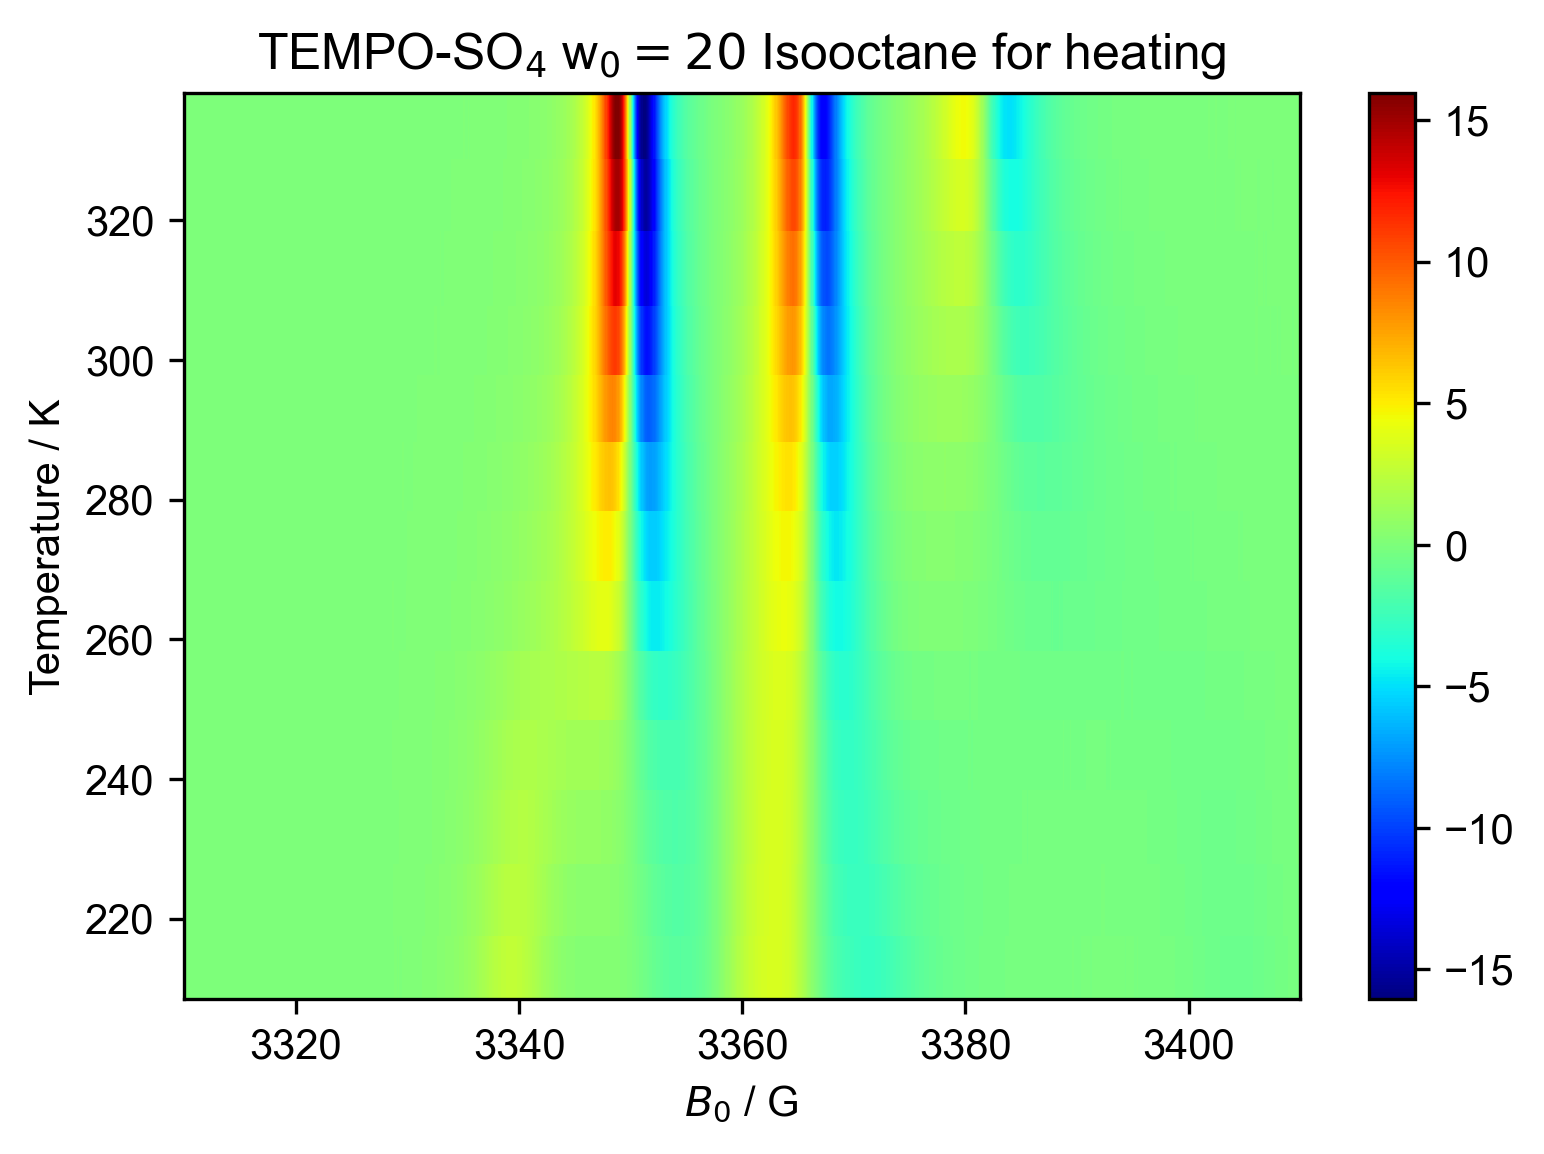

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ Isooctane for heating")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating')

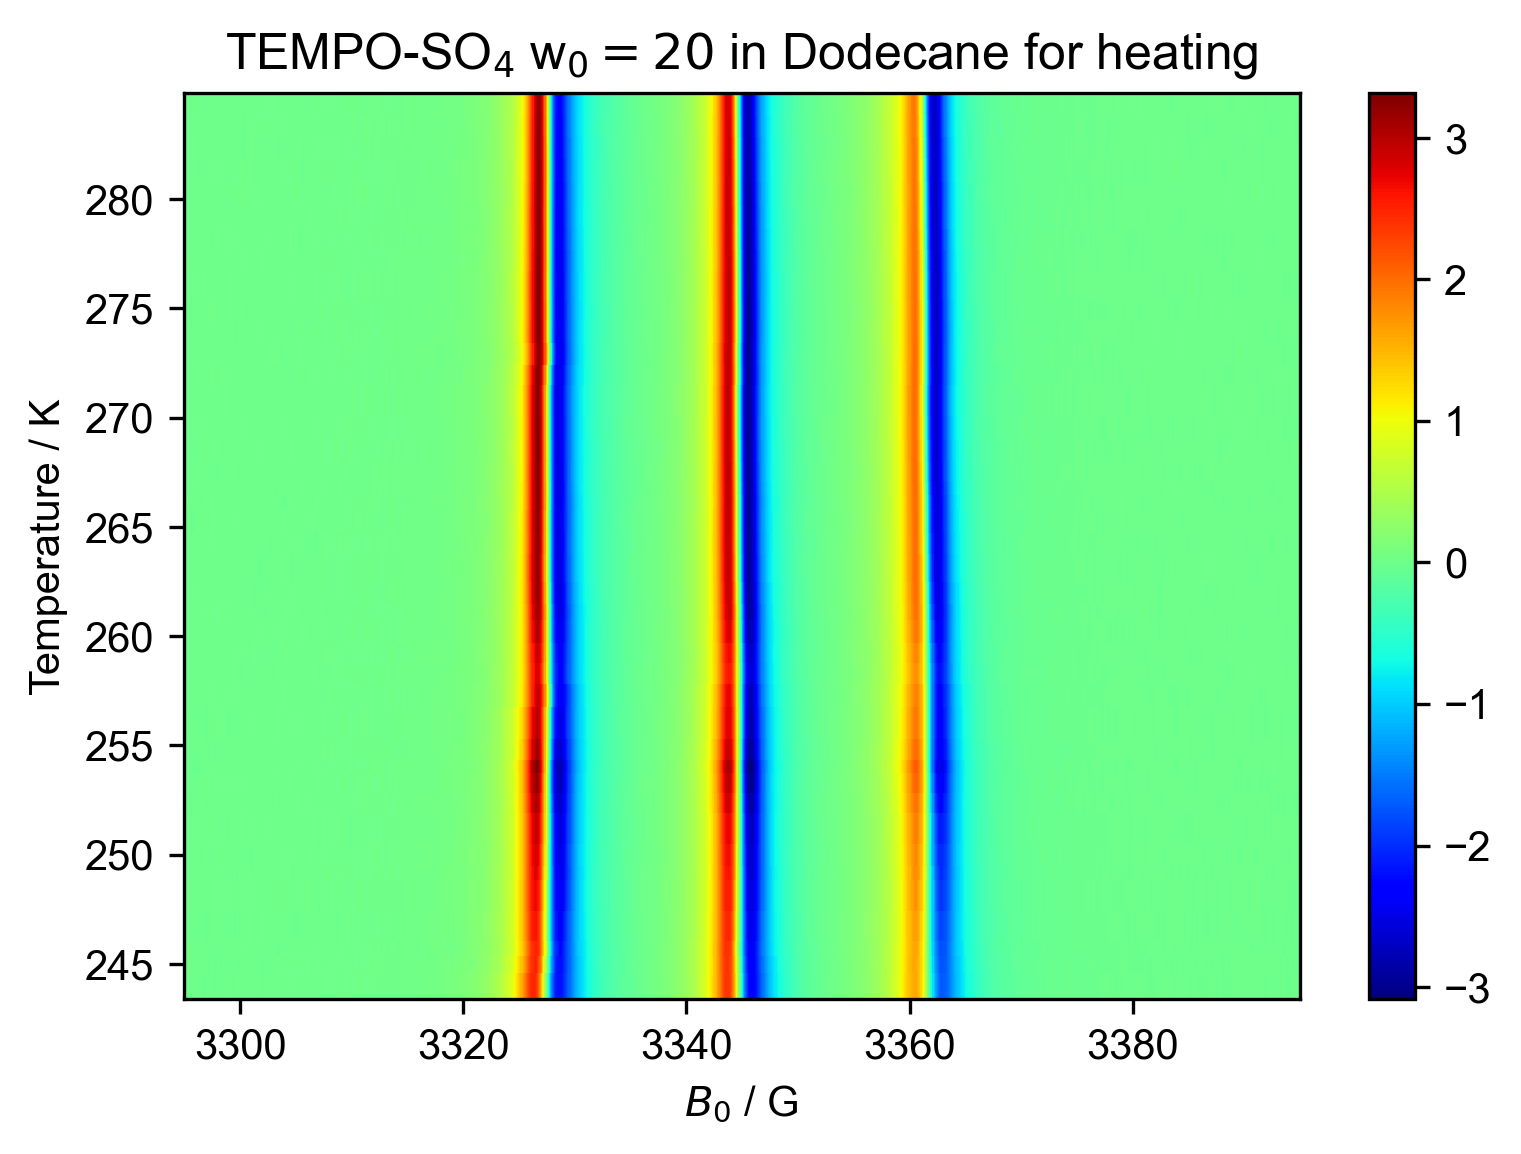

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating")

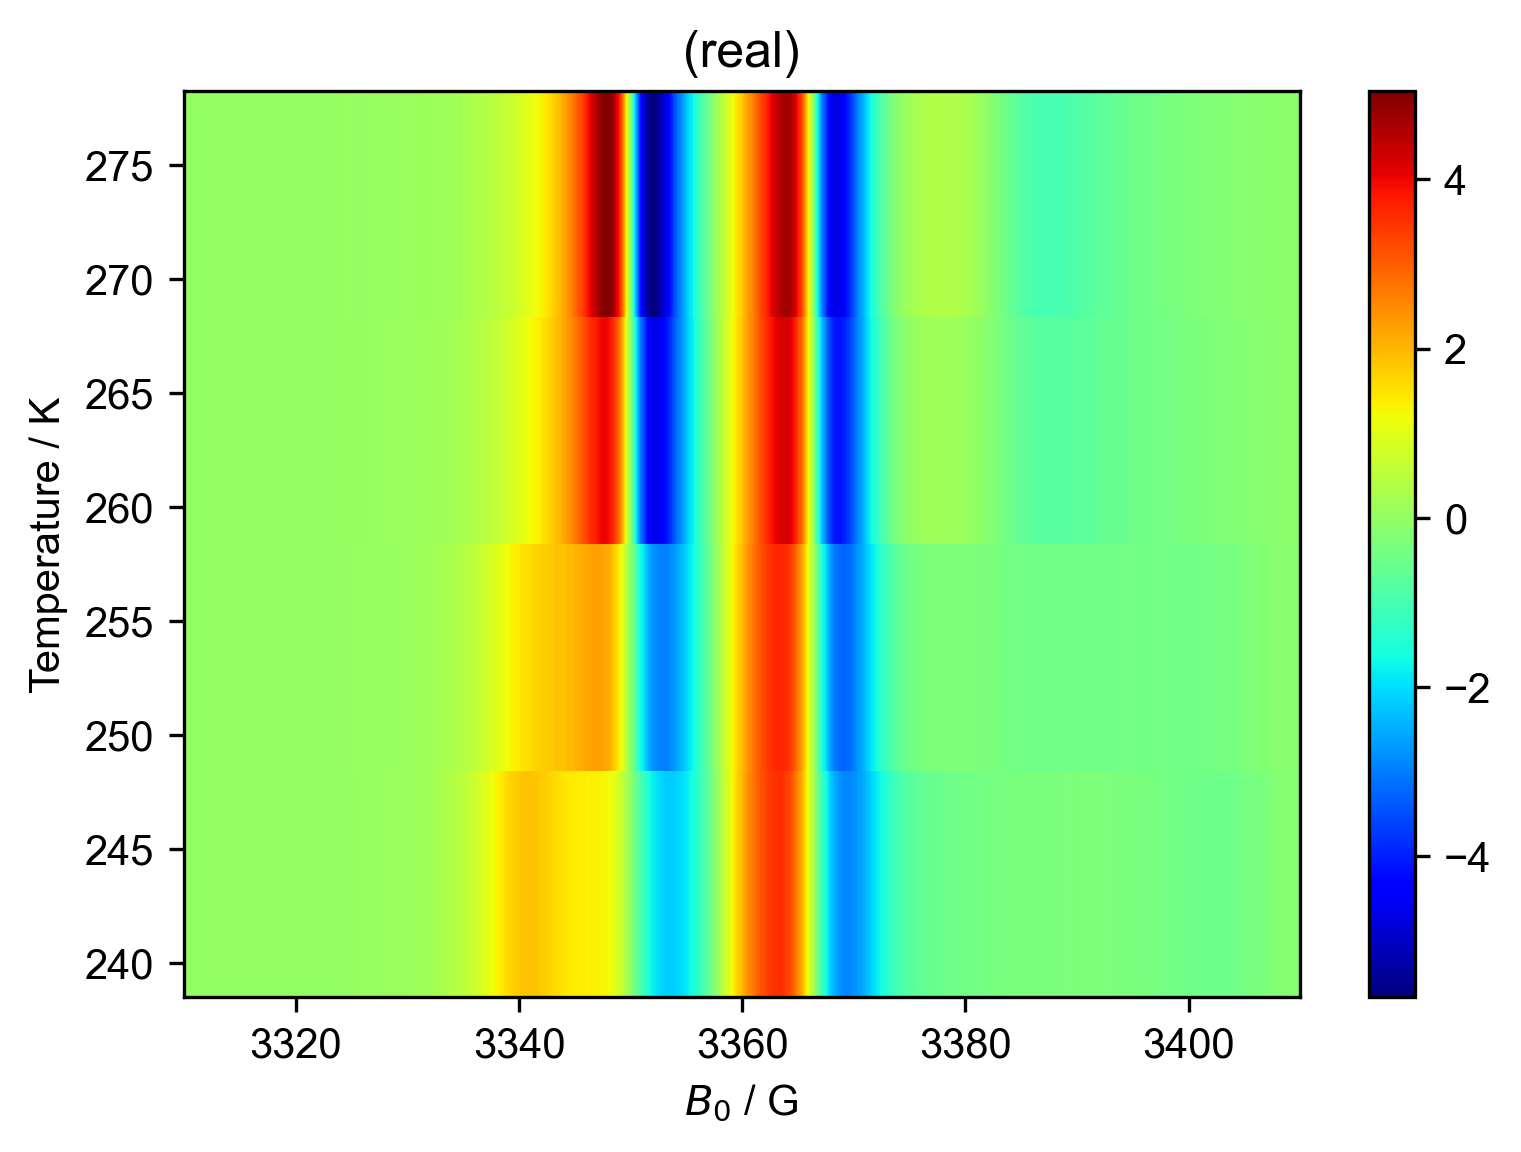

In [9]:
figure(dpi=300)
d1['Temperature':(243,283)].pcolor()

From this, I learn that
it's easiest to show the 1D plots above and below the transition

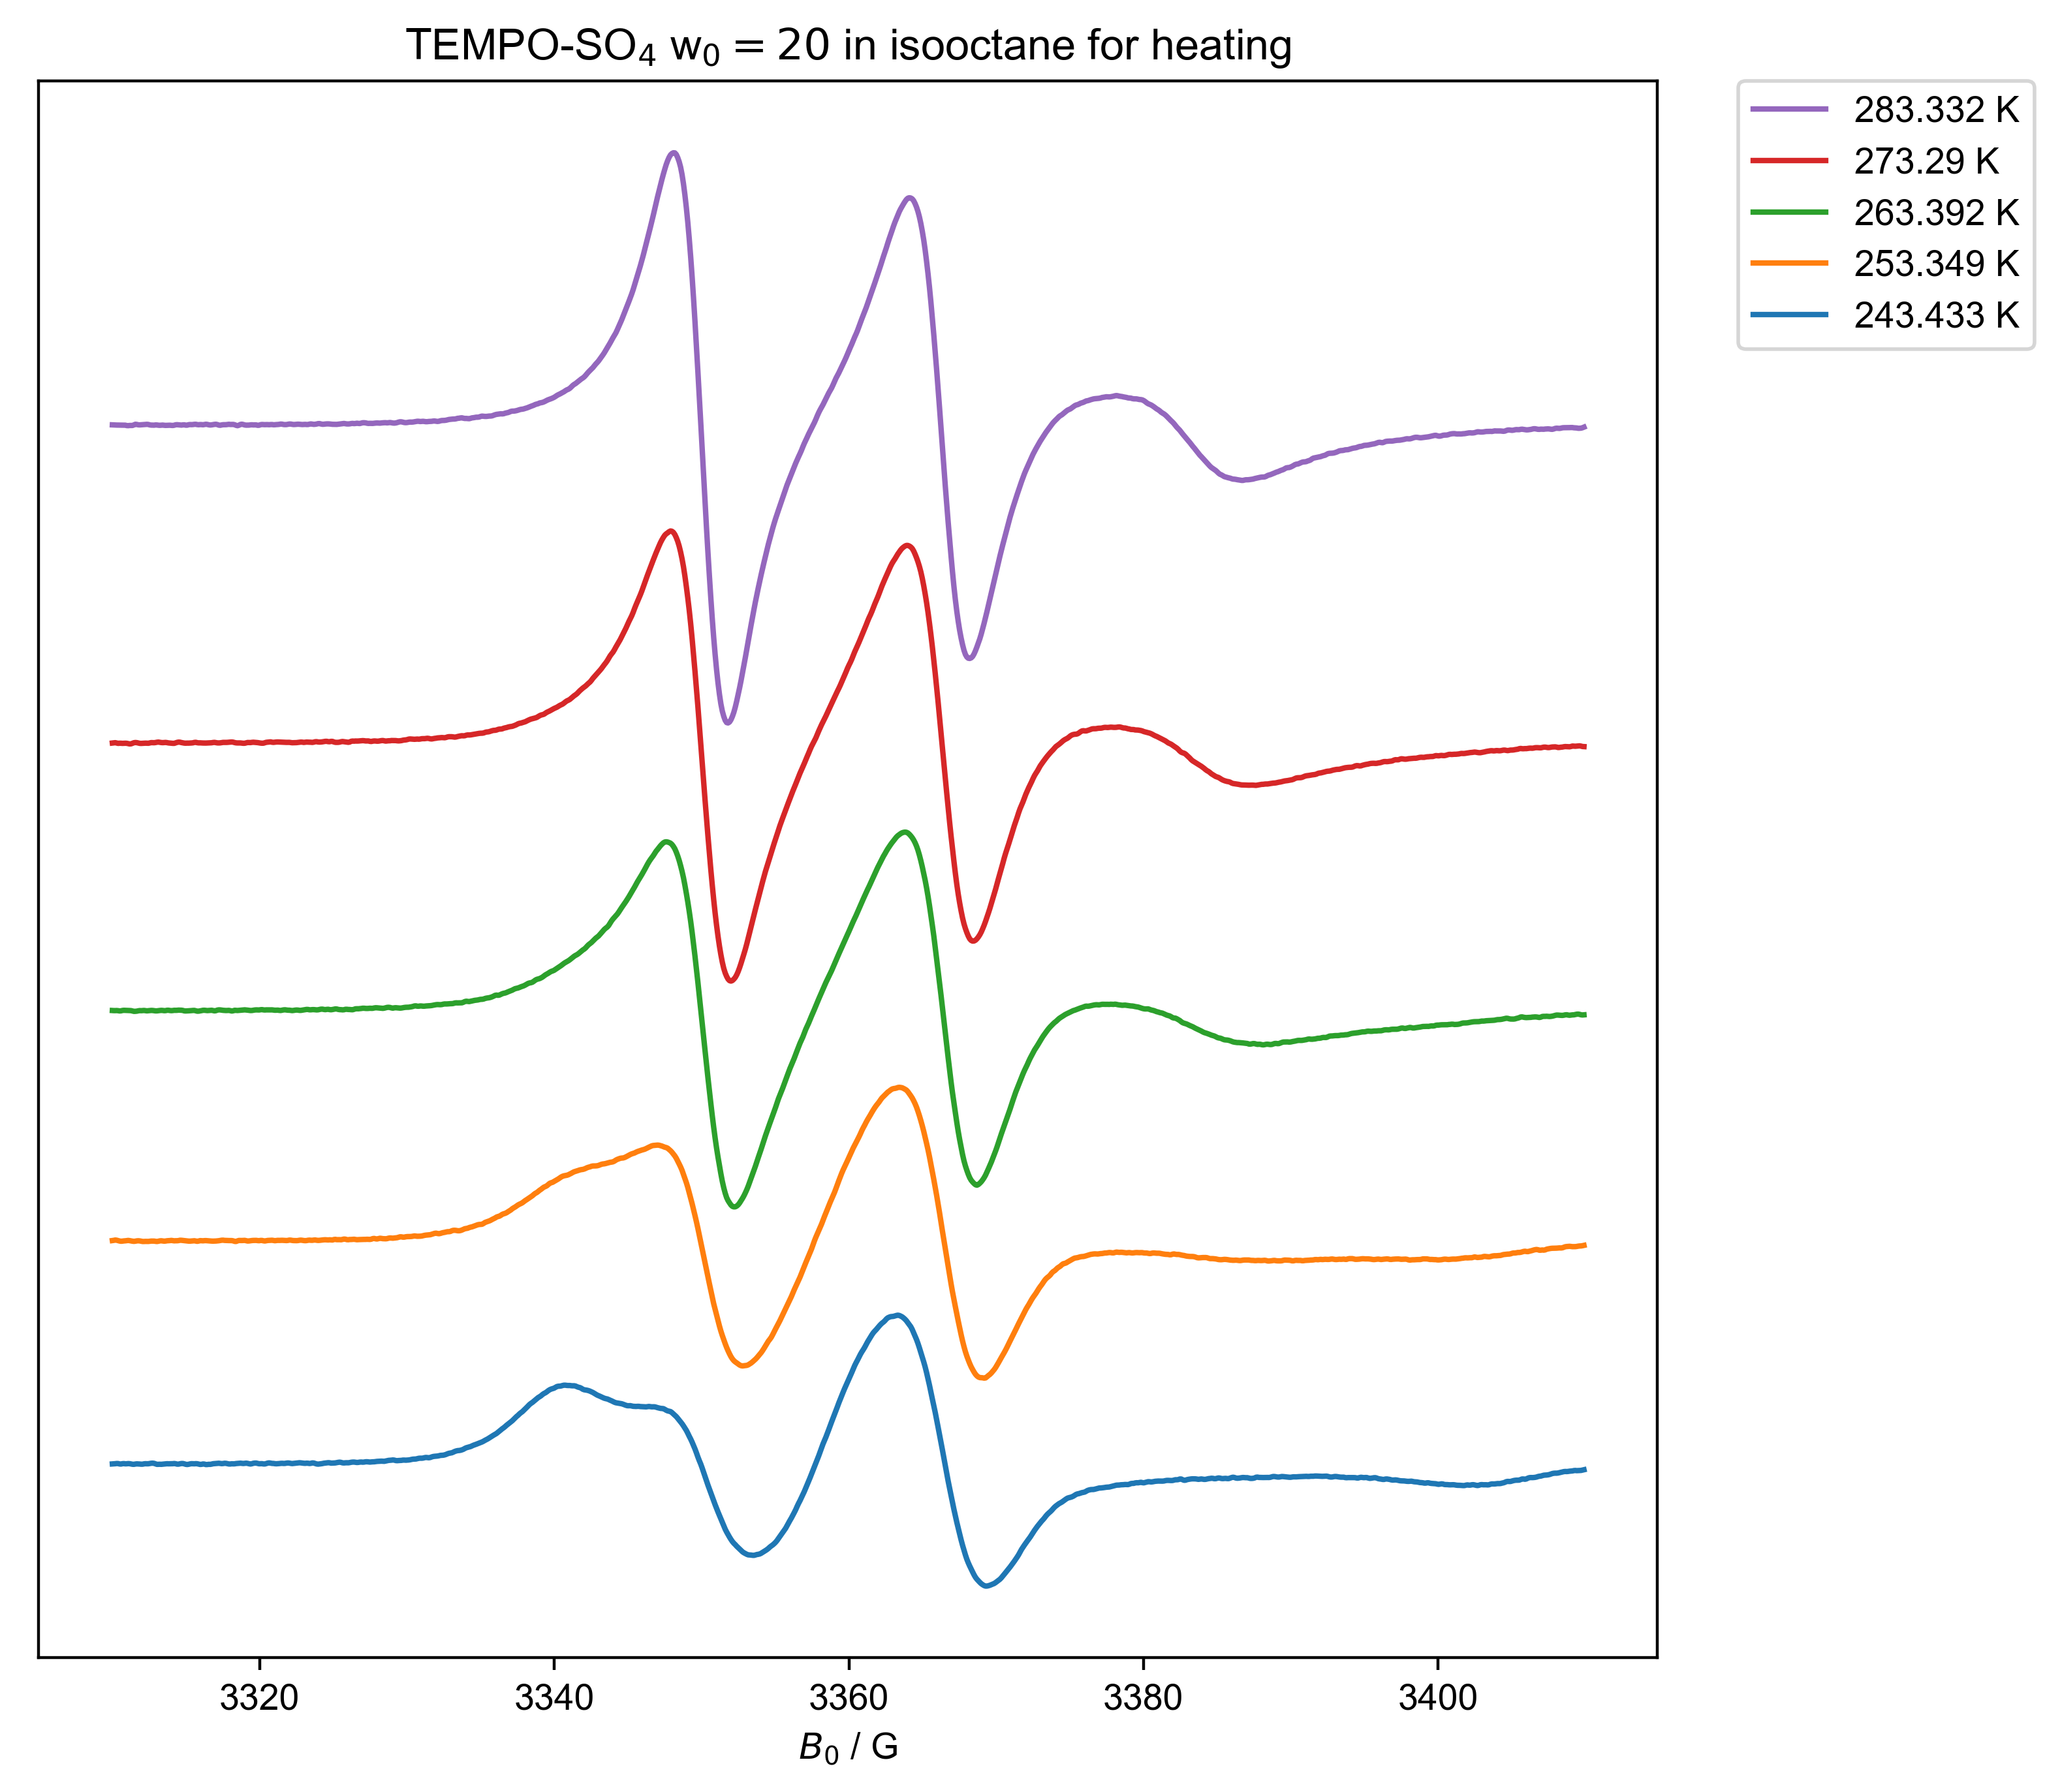

In [10]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for heating", (243, 284))
 ]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 20
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

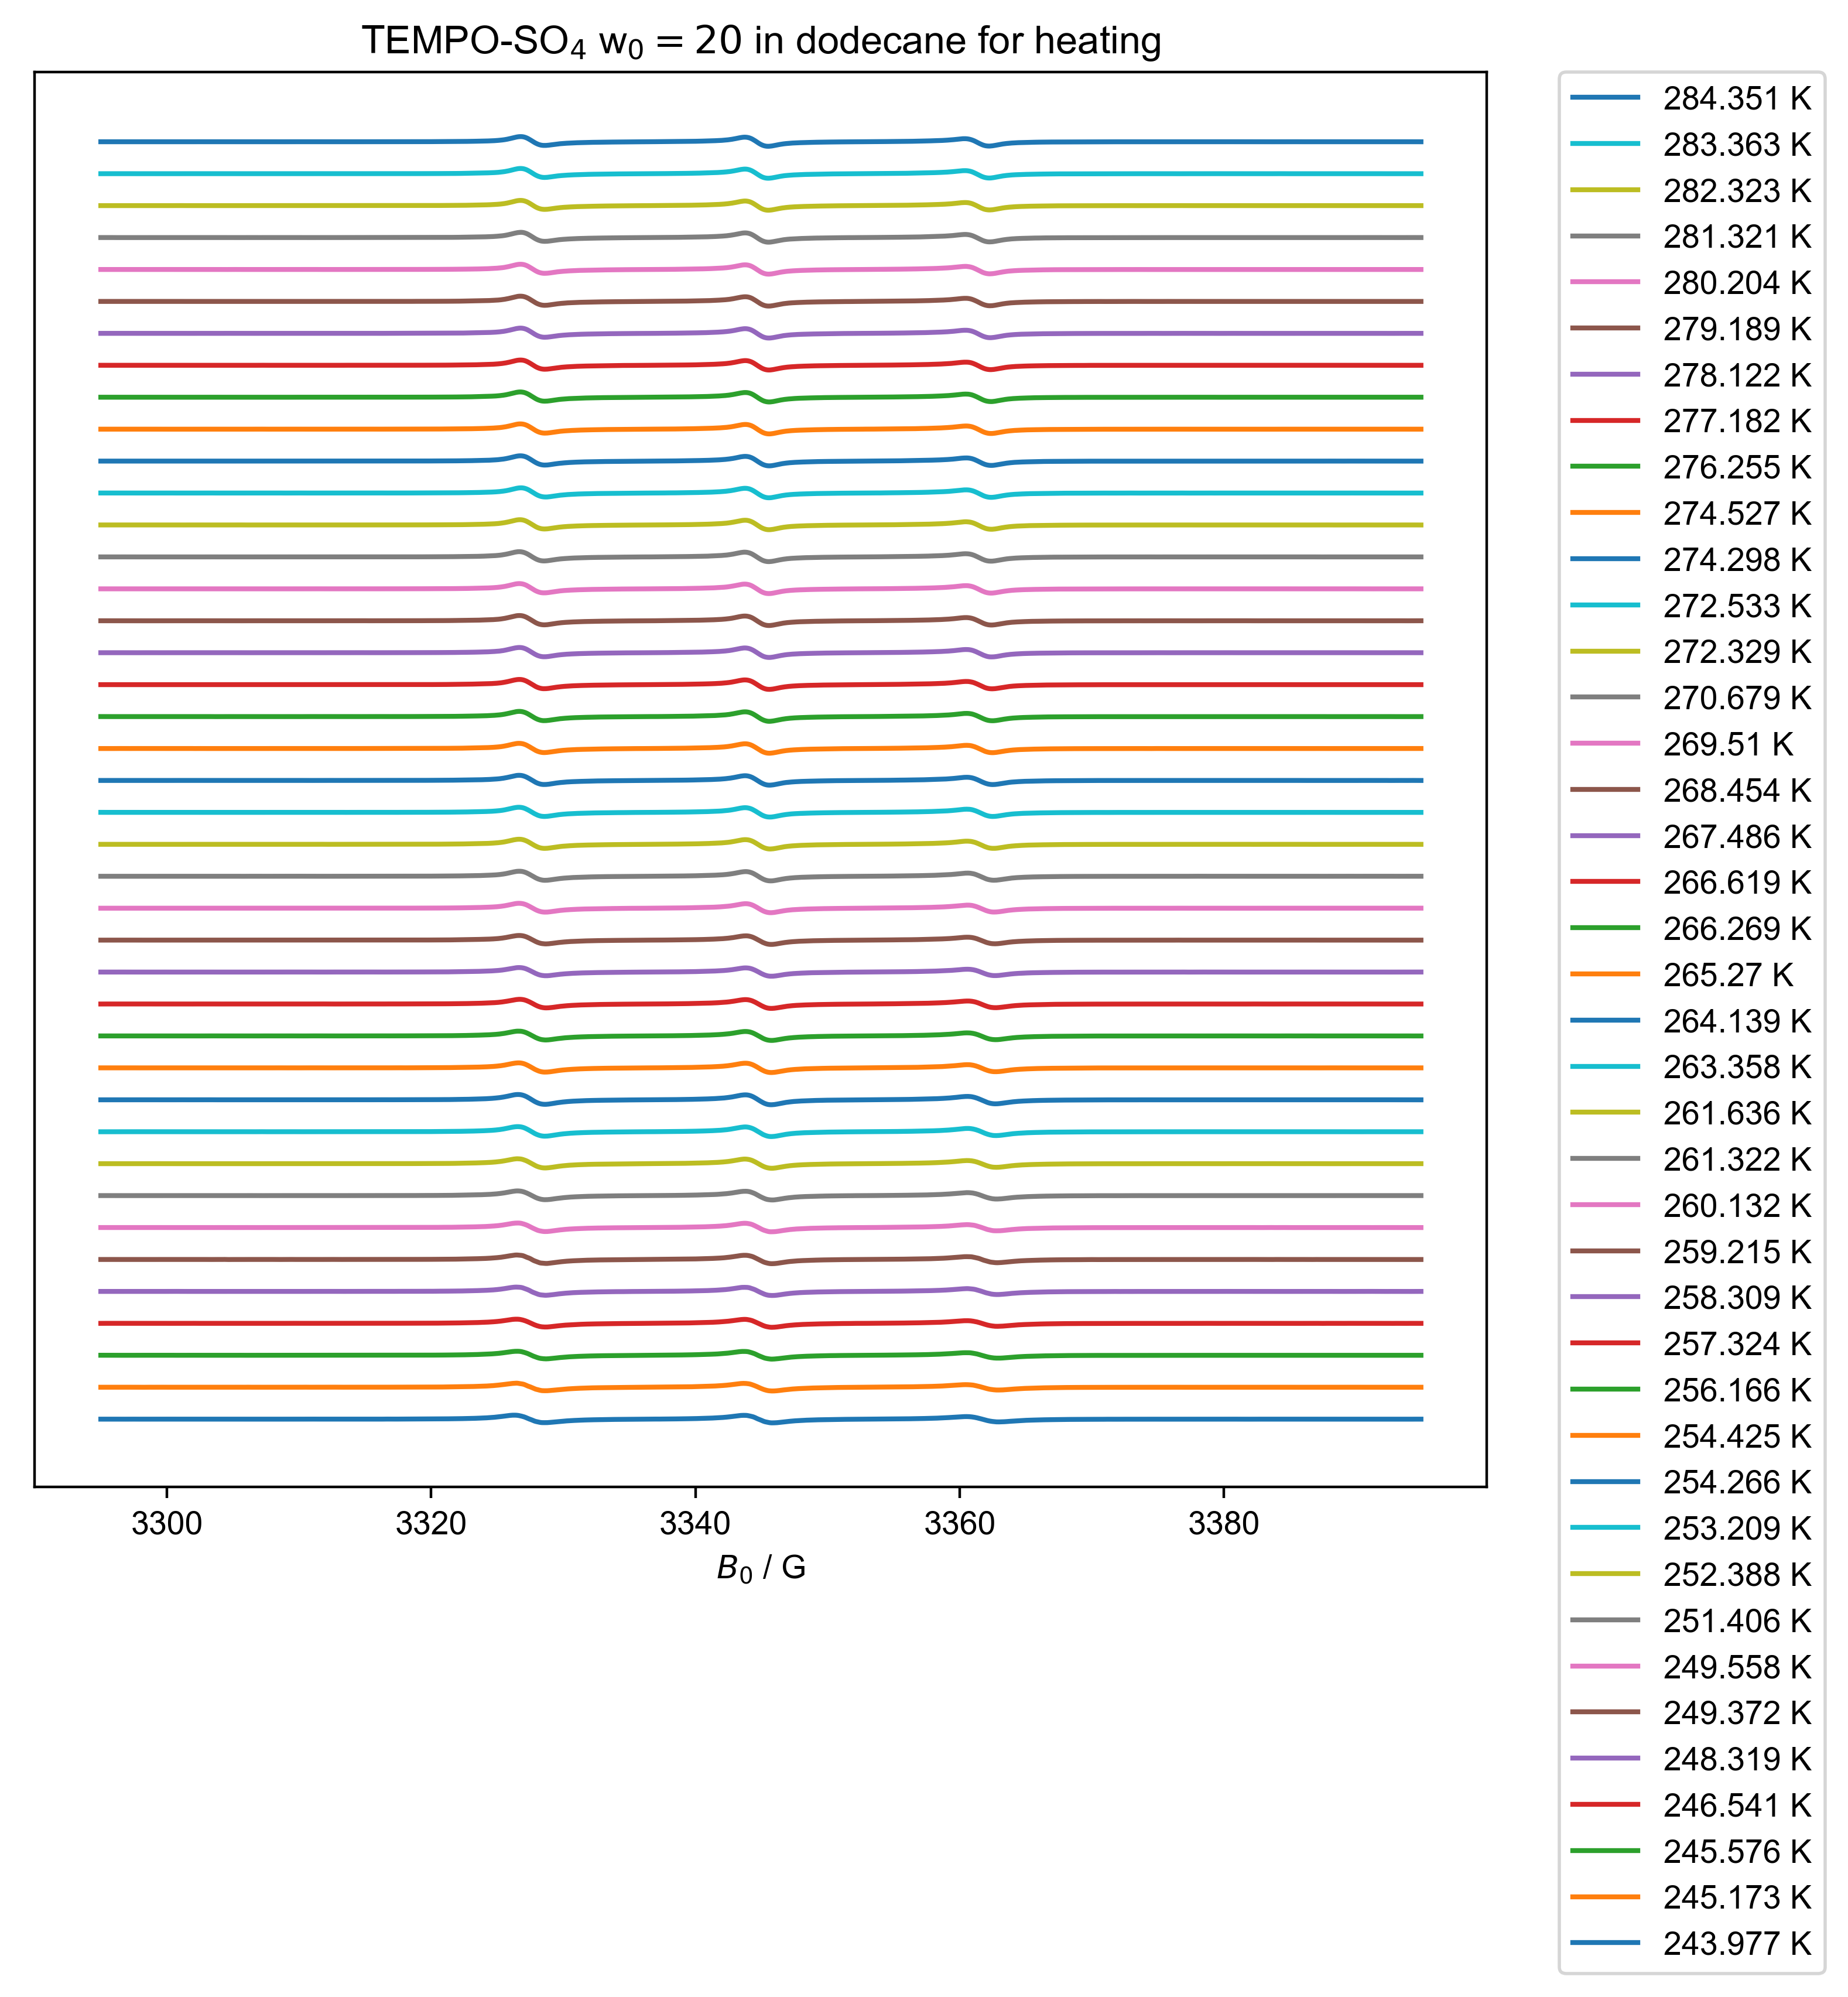

In [11]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in dodecane for heating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
#         offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # to get legend reversed
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

        
#     fancy_legend()

[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


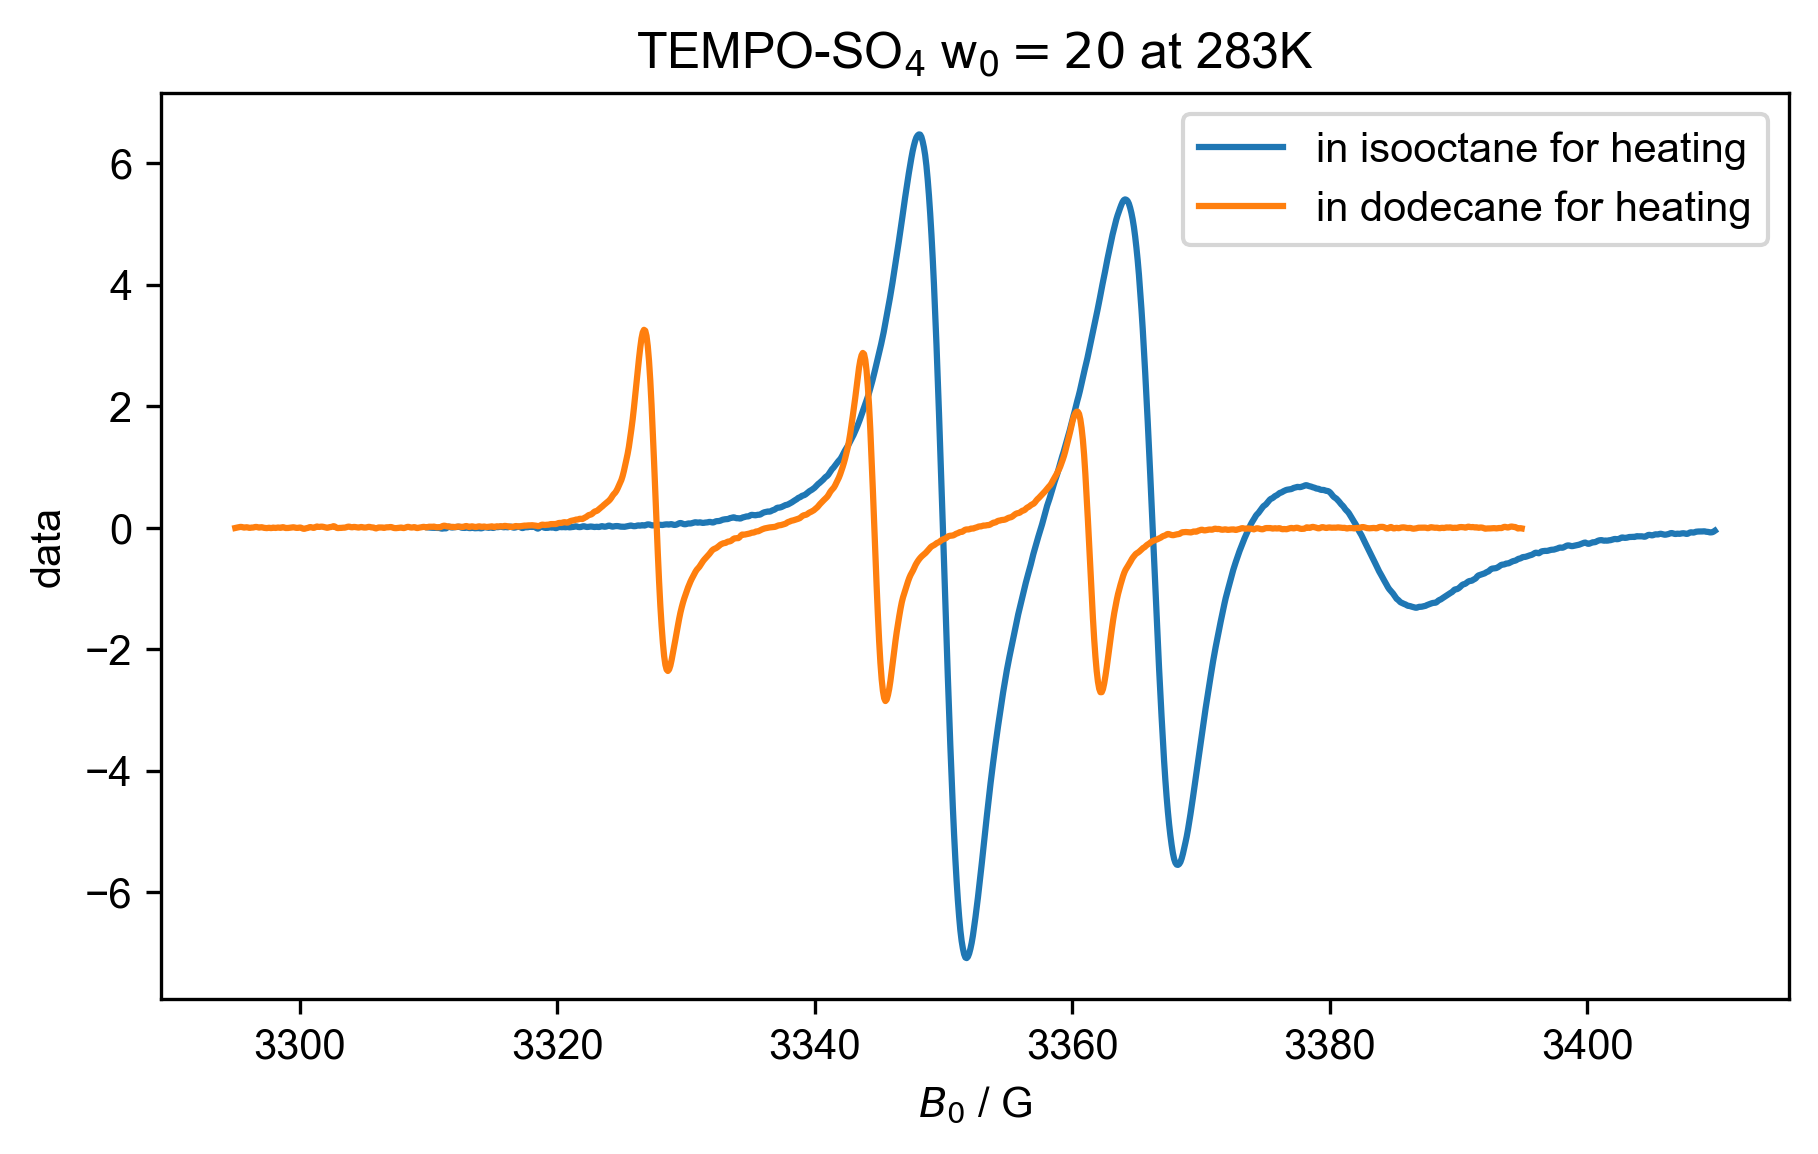

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":283], label="in isooctane for heating")
plot(d2["Temperature":283], label="in dodecane for heating")
title("TEMPO-SO$_4$ w$_0= 20$ at 283K")
# title("at 283K")
legend()

[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


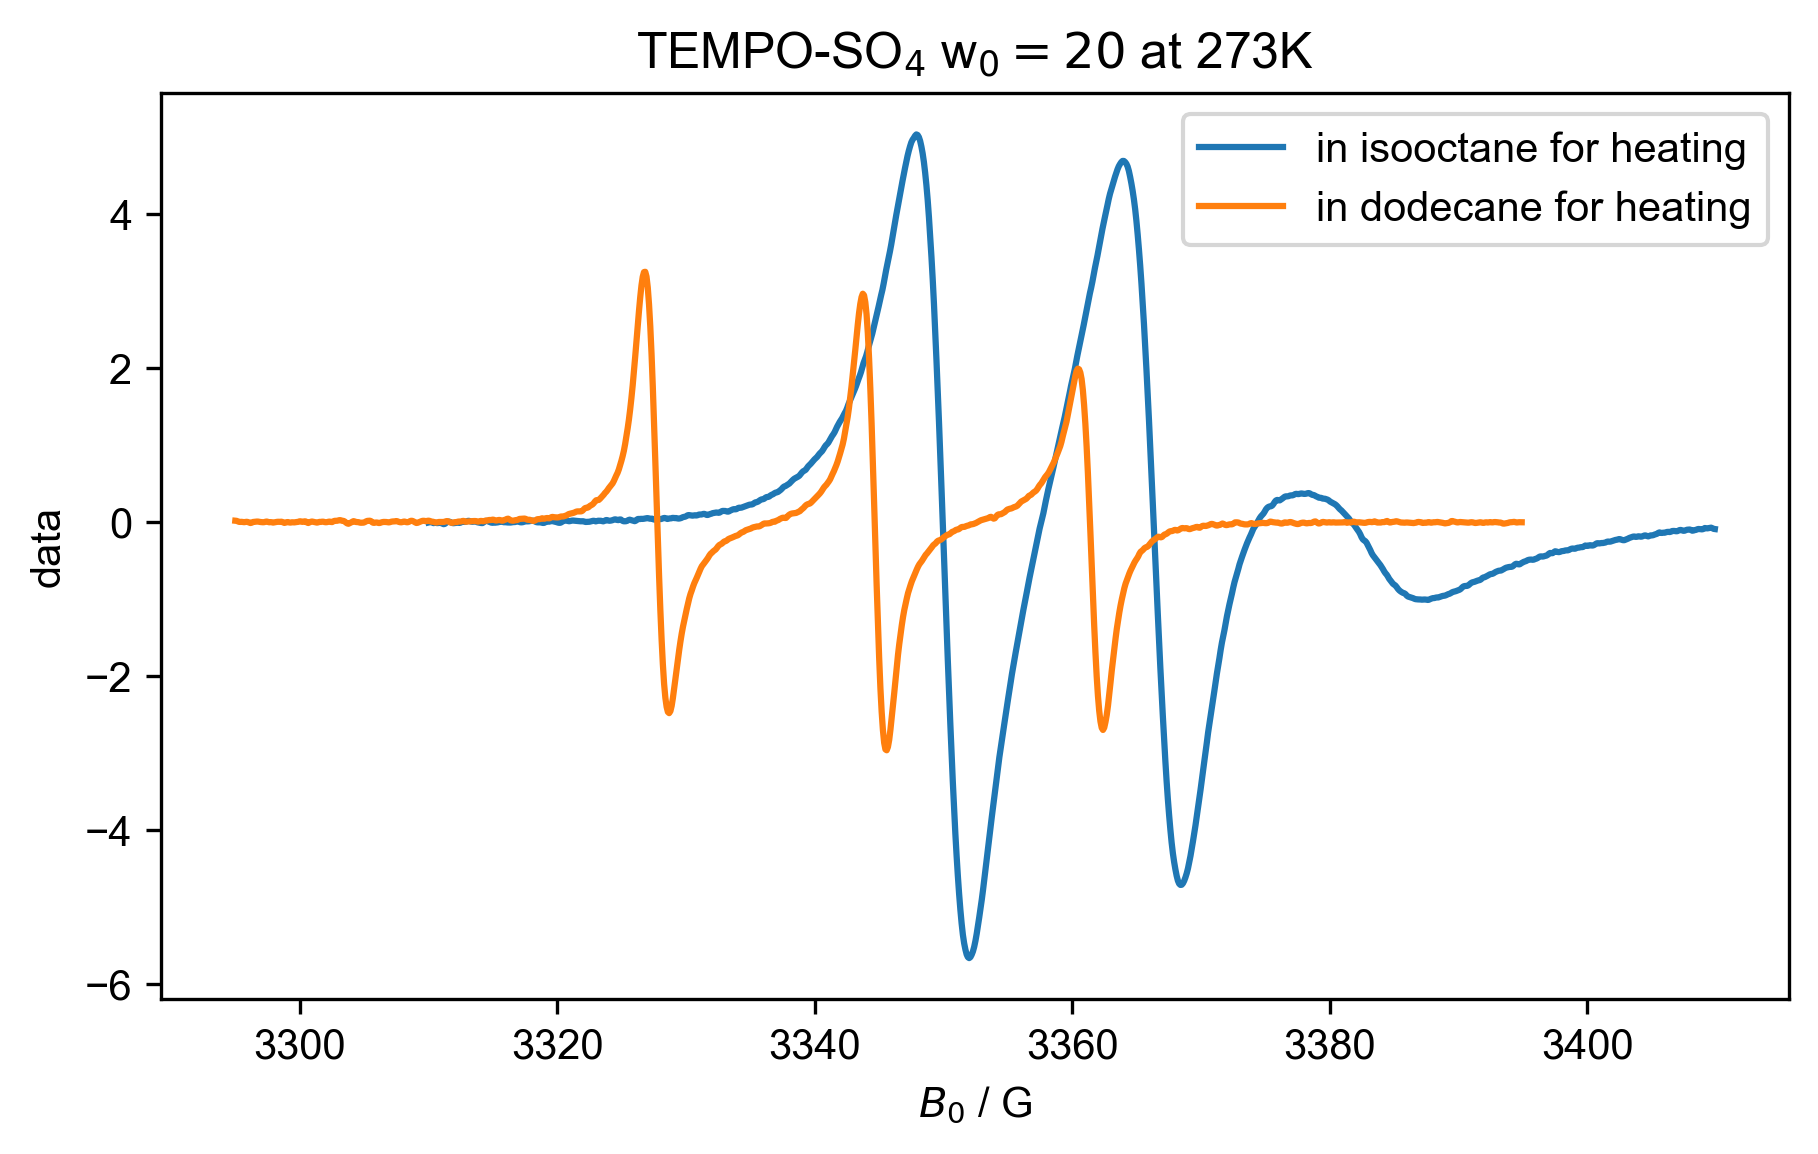

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":273], label="in isooctane for heating")
plot(d2["Temperature":273], label="in dodecane for heating")
title("TEMPO-SO$_4$ w$_0= 20$ at 273K")
# title("at 283K")
legend()

[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


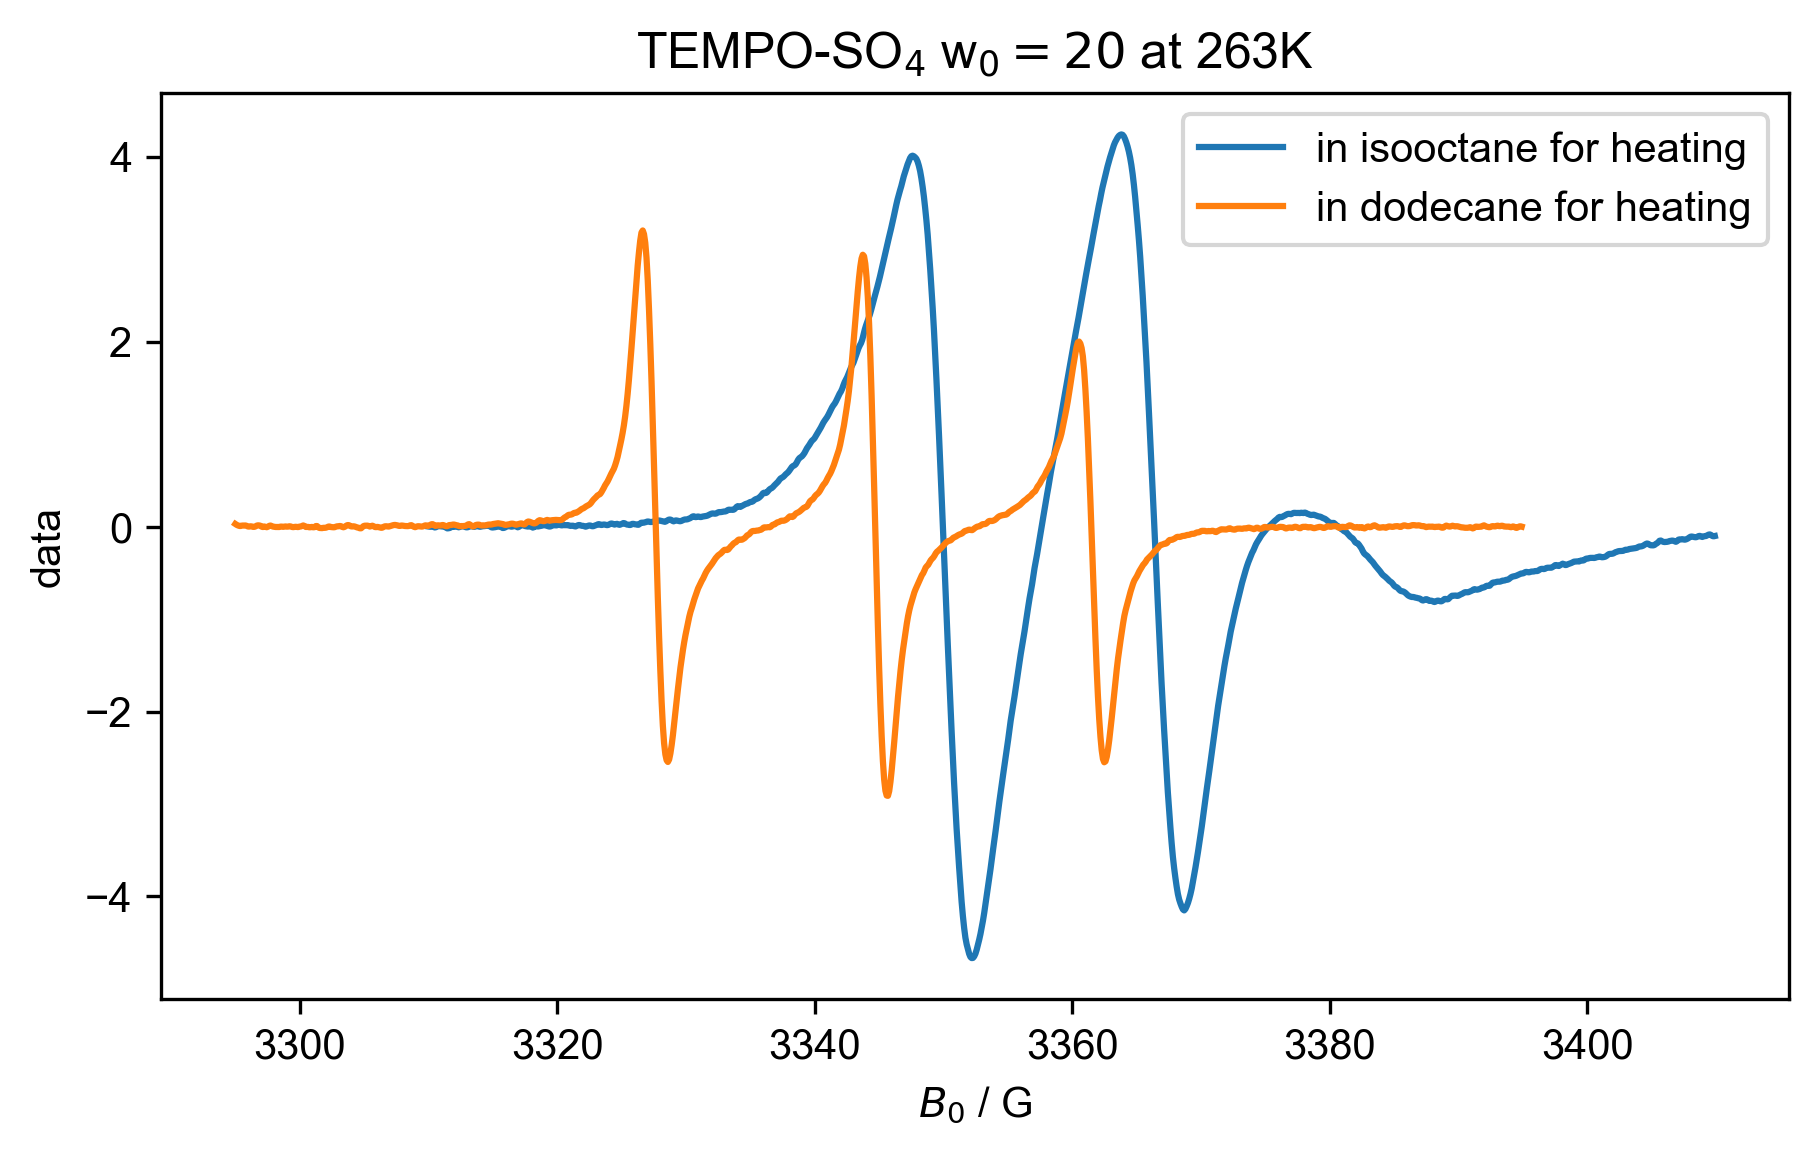

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":263], label="in isooctane for heating")
plot(d2["Temperature":263], label="in dodecane for heating")
title("TEMPO-SO$_4$ w$_0= 20$ at 263K")
legend()

[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


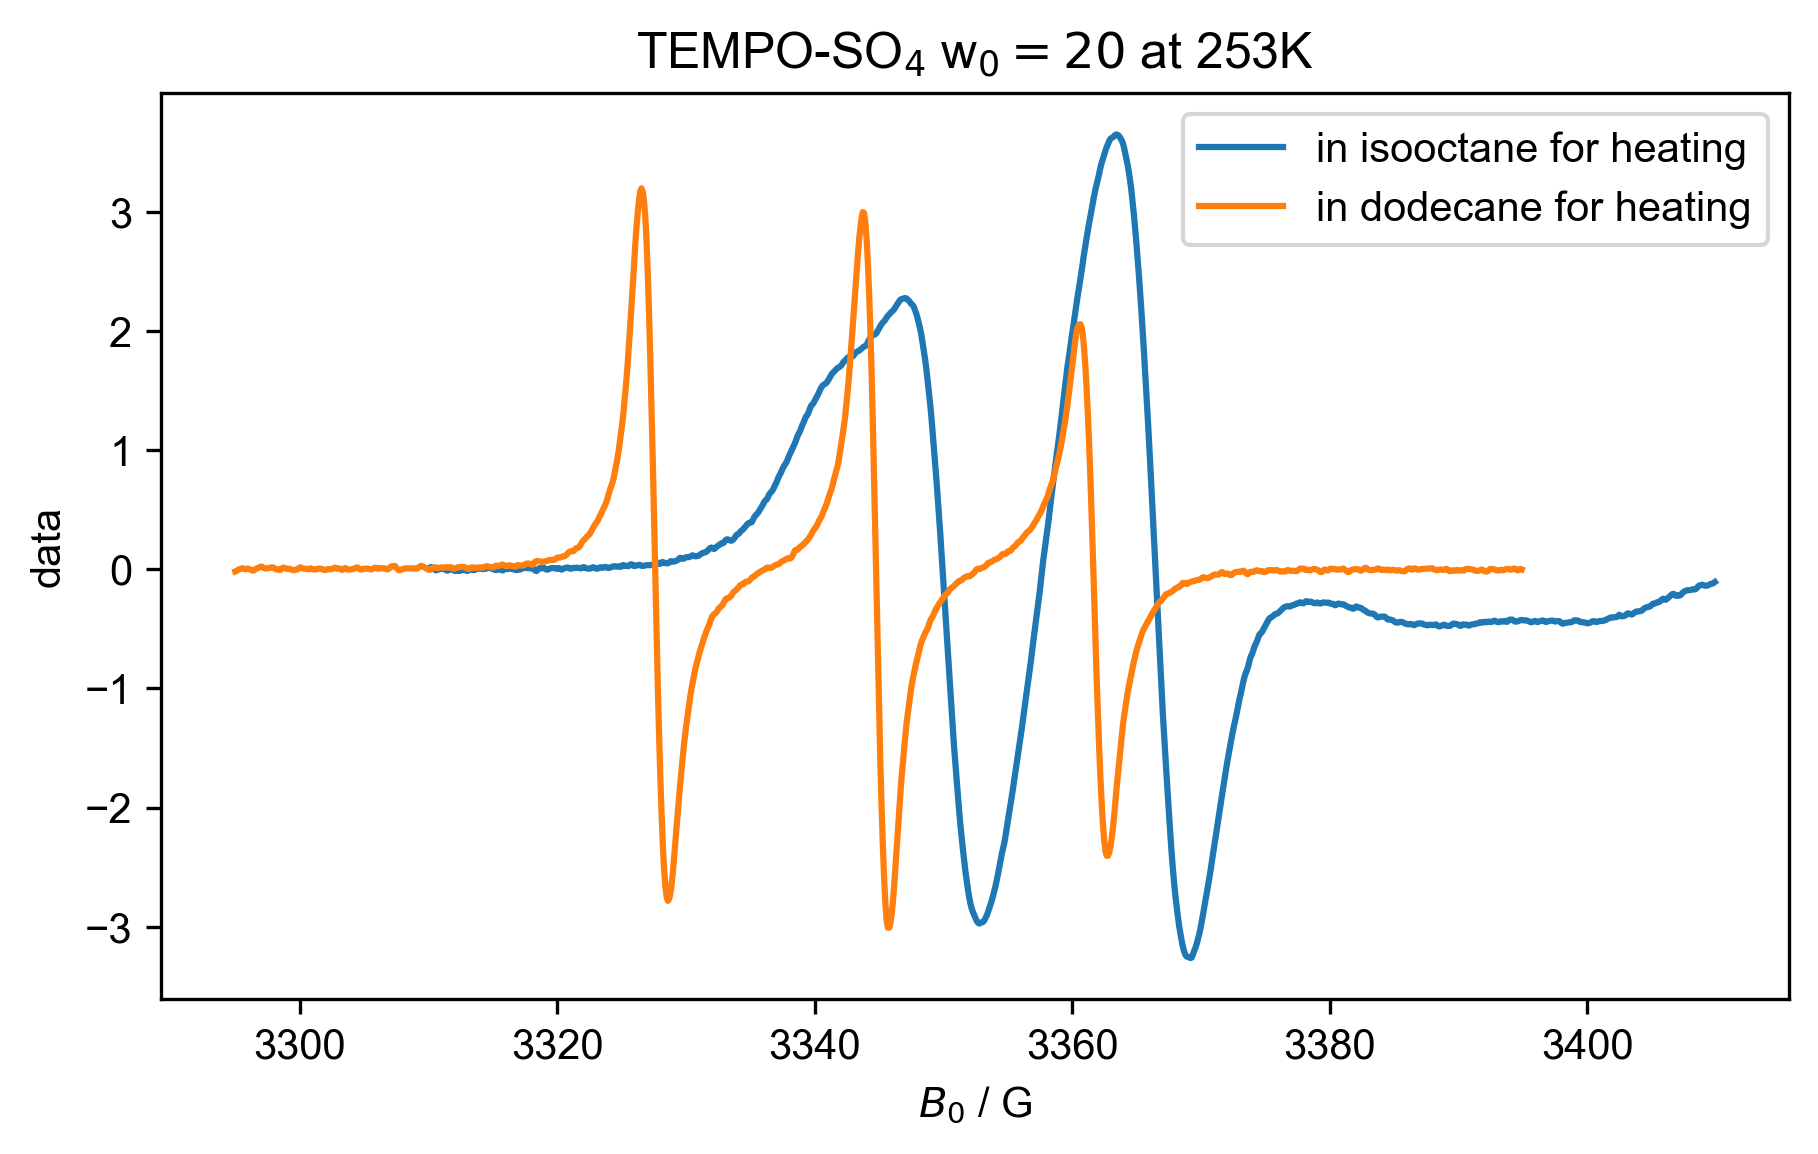

In [15]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":253], label="in isooctane for heating")
plot(d2["Temperature":253], label="in dodecane for heating")
title("TEMPO-SO$_4$ w$_0= 20$ at 253K")
legend()

[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


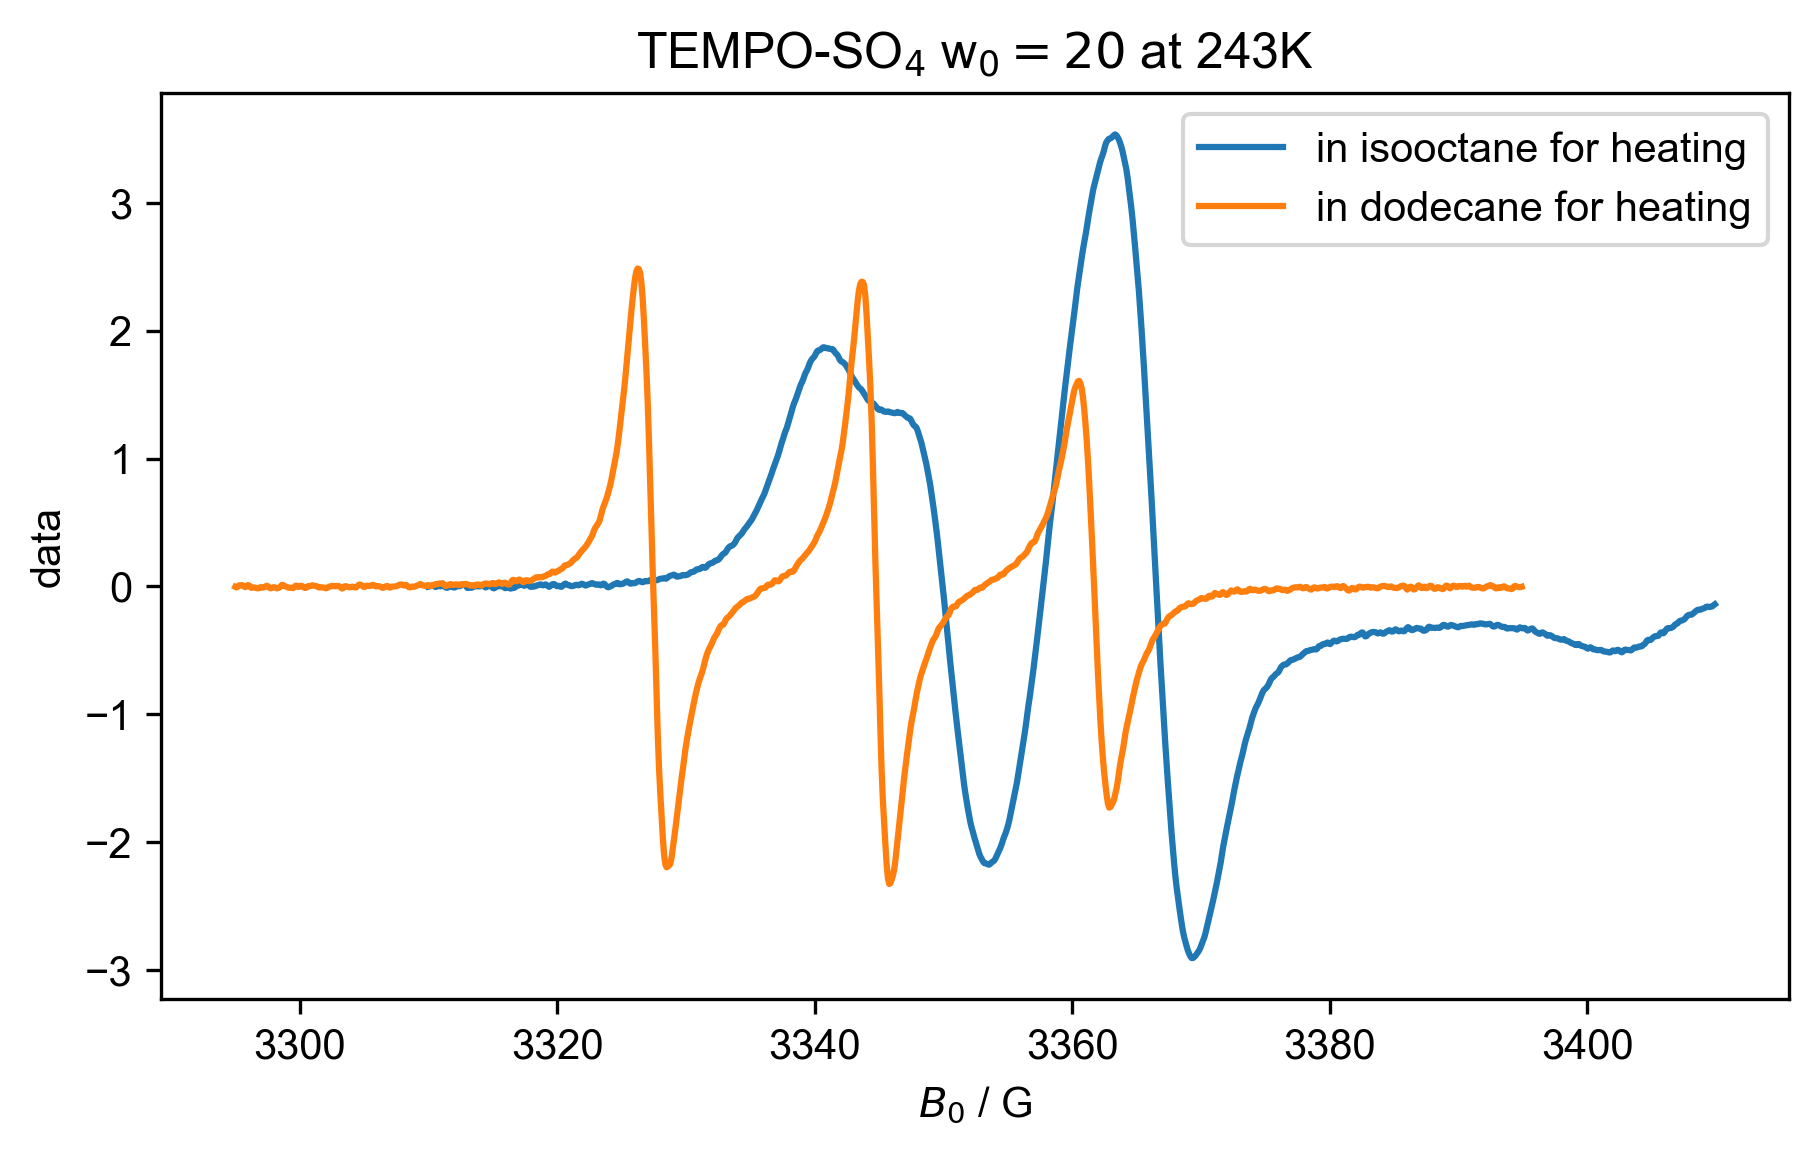

In [16]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":243], label="in isooctane for heating")
plot(d2["Temperature":243], label="in dodecane for heating")
title("TEMPO-SO$_4$ w$_0= 20$ at 243K")
legend()

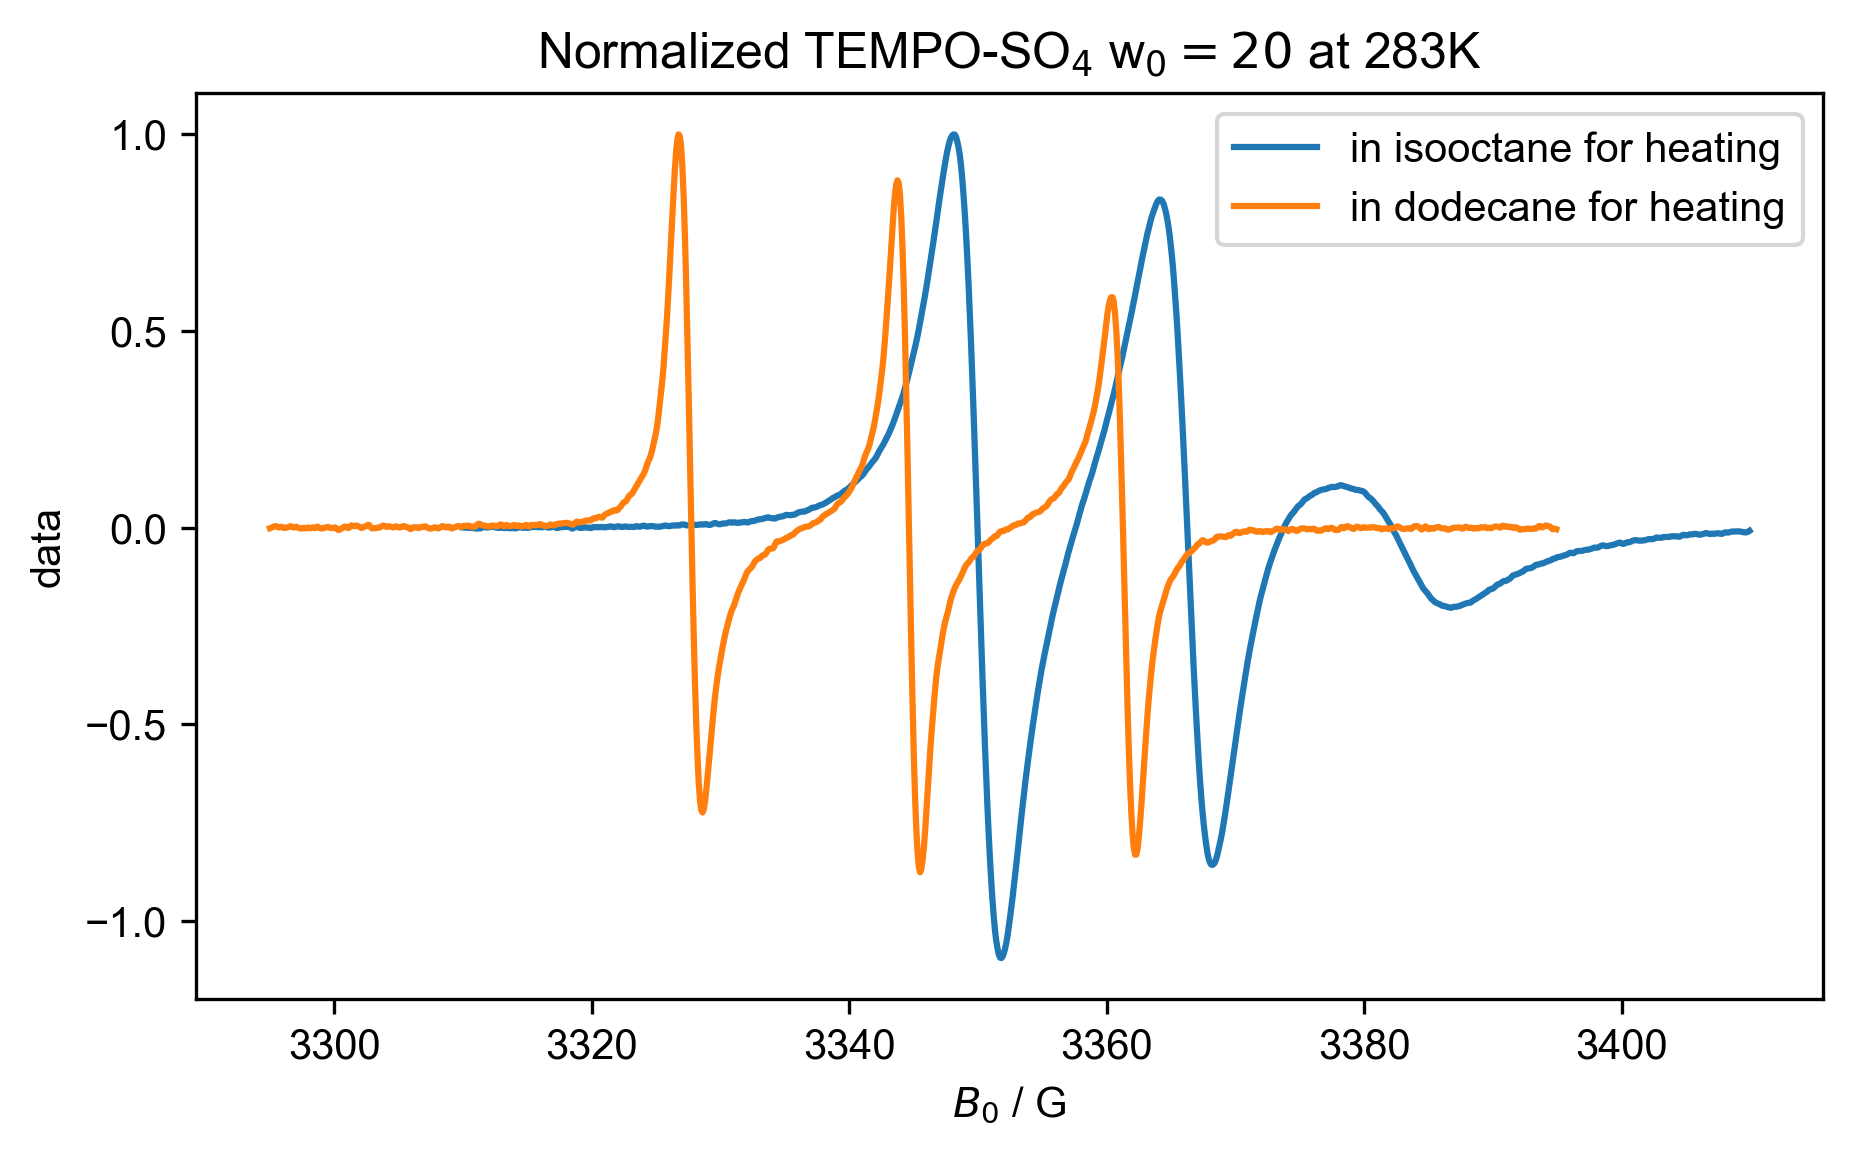

In [17]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "in isooctane for heating")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "in dodecane for heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ at 283K")
legend()

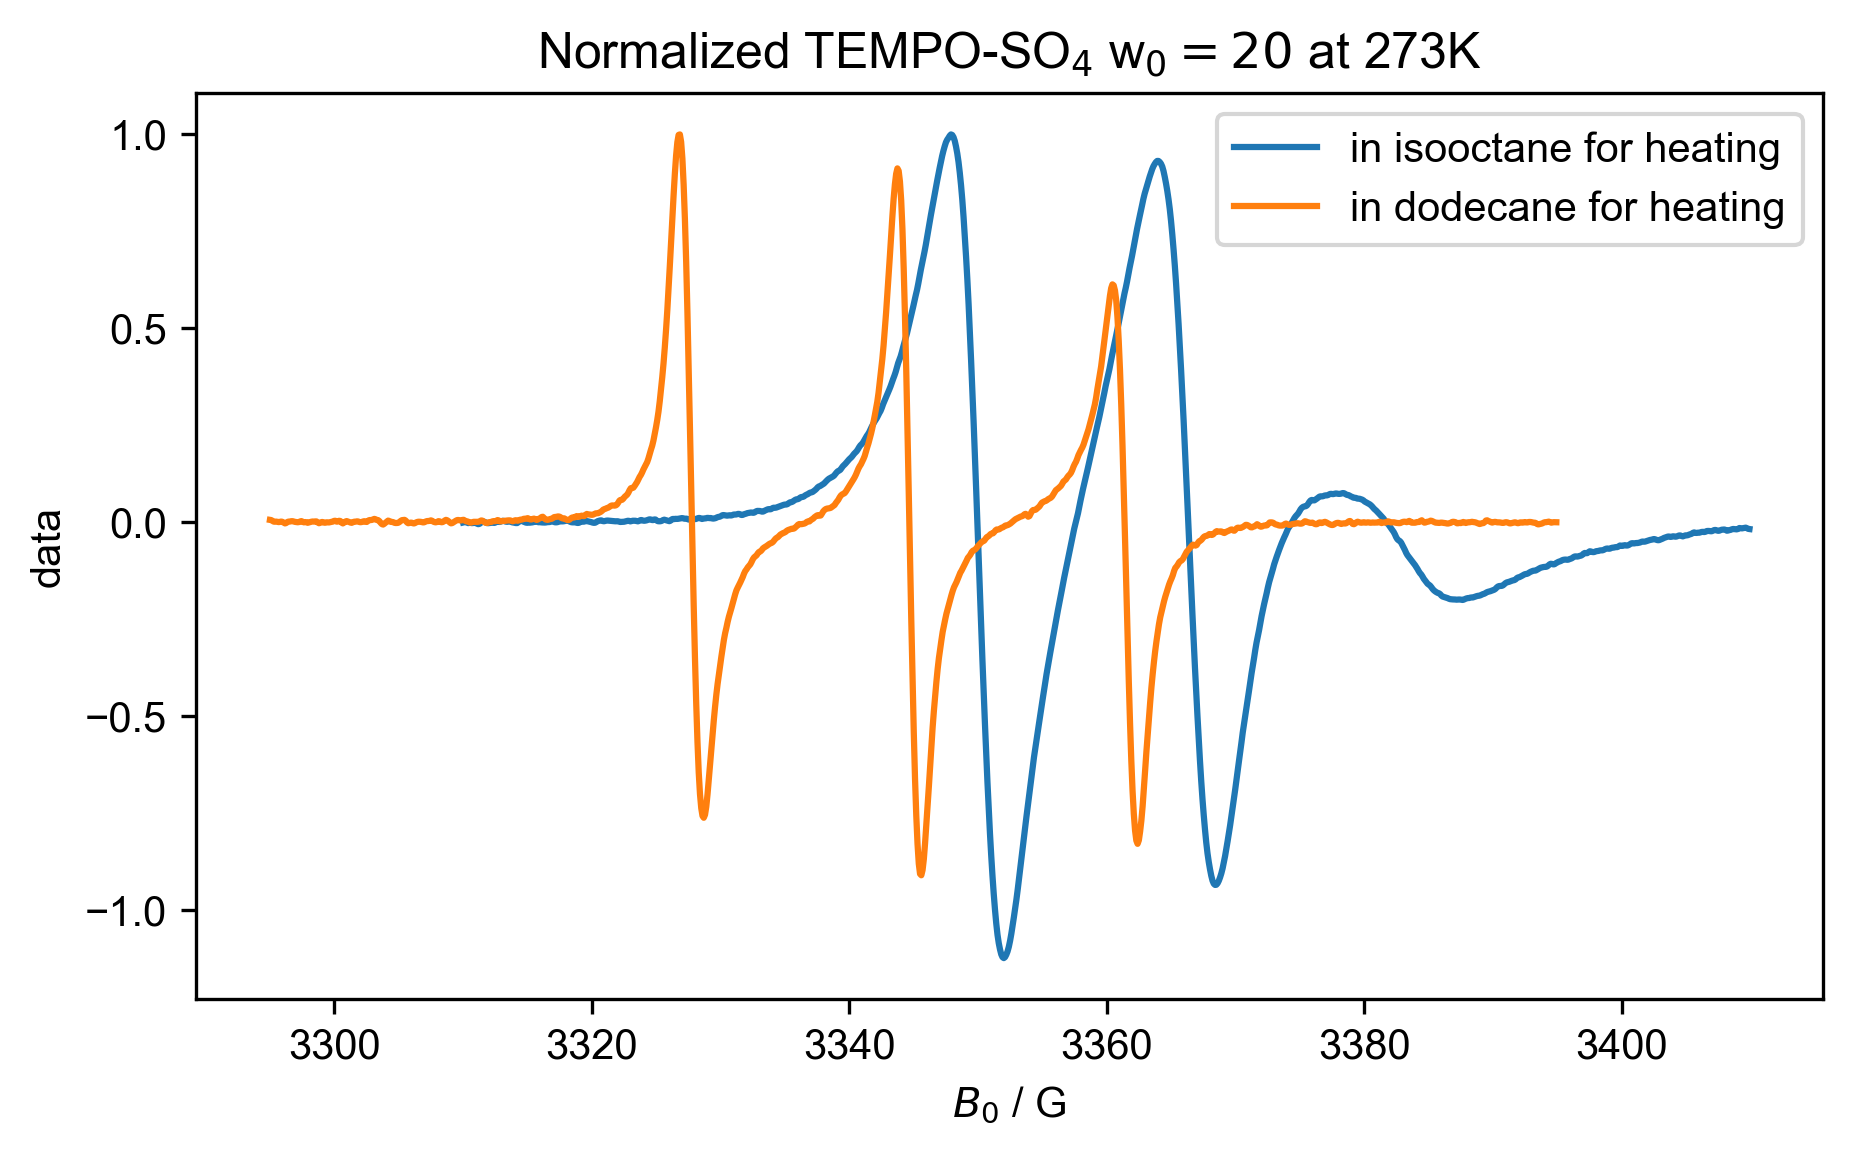

In [18]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 273] / d1["Temperature": 273].max(), label= "in isooctane for heating")
plot(d2["Temperature": 273] / d2["Temperature": 273].max(), label= "in dodecane for heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ at 273K")
legend()

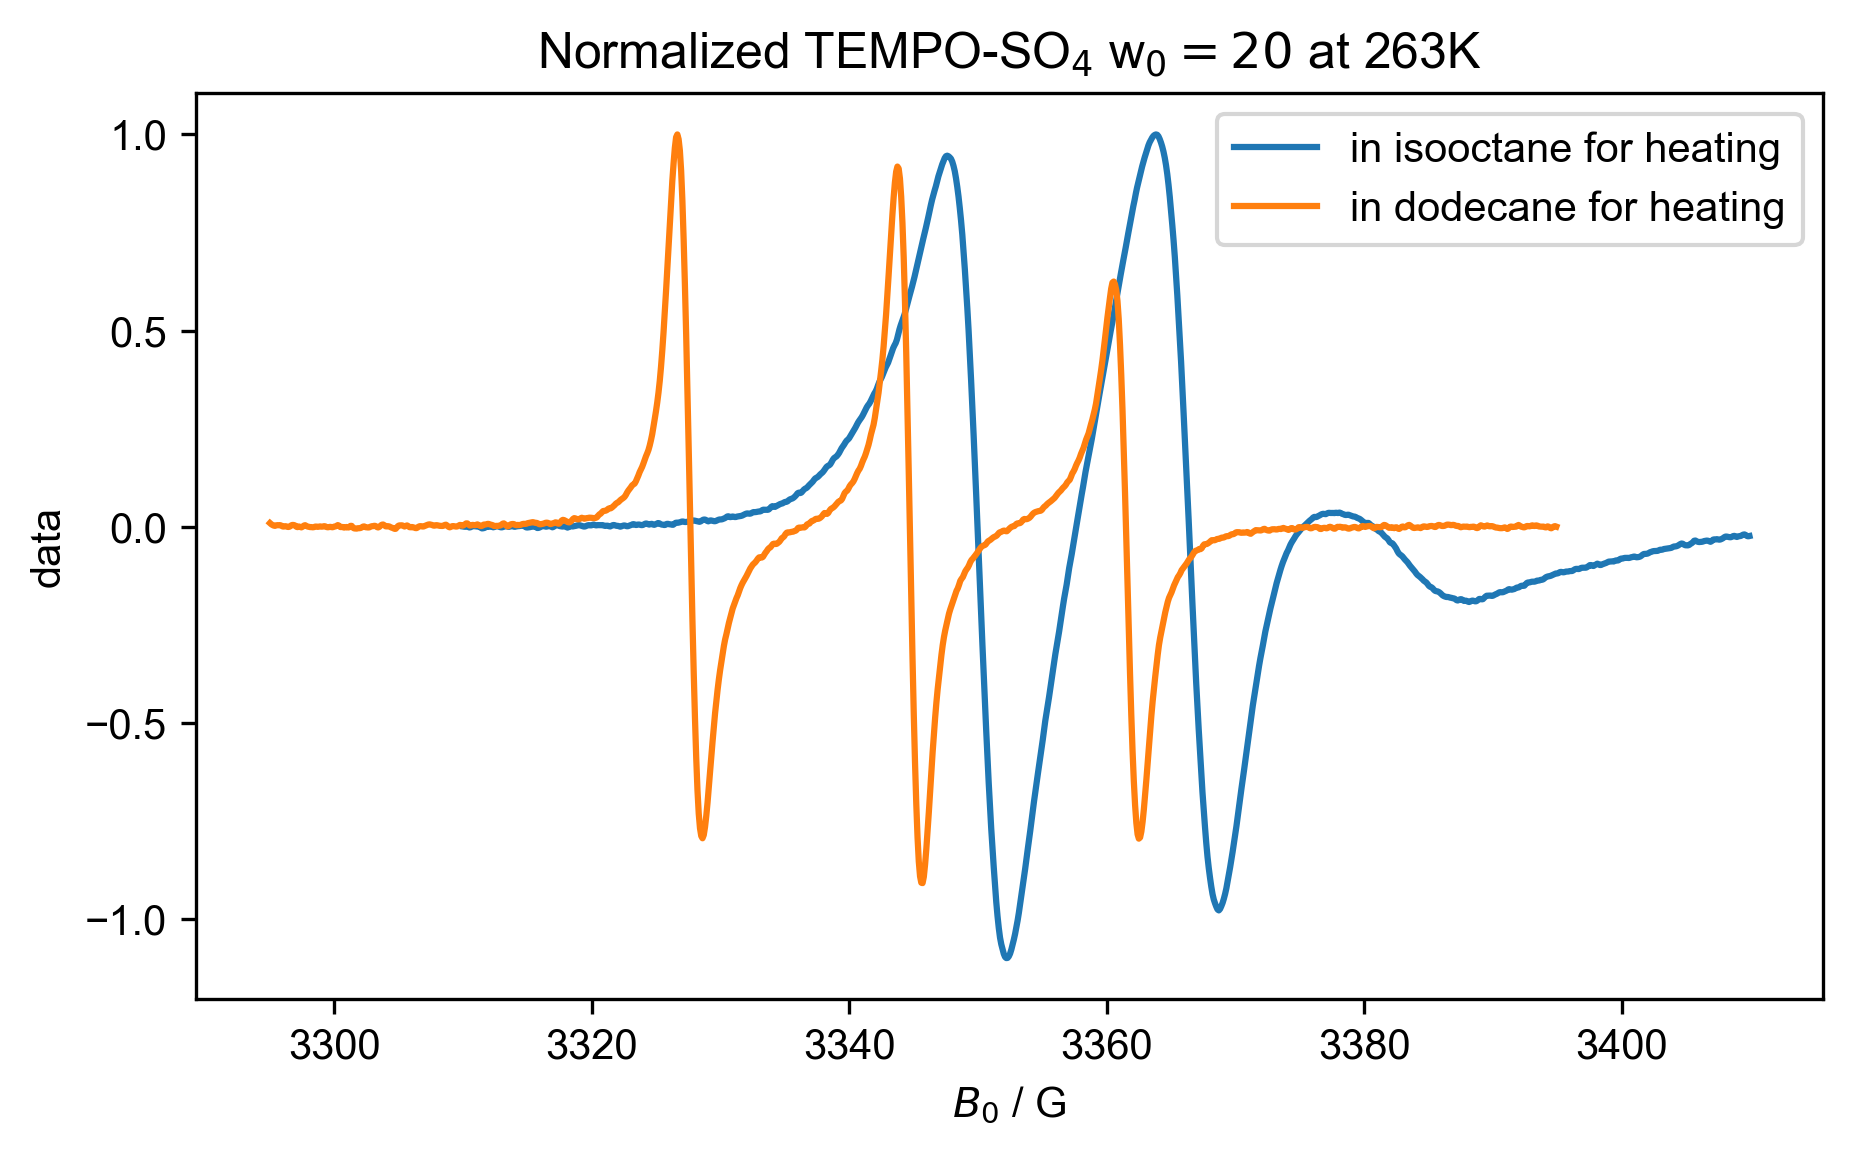

In [19]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 263] / d1["Temperature": 263].max(), label= "in isooctane for heating")
plot(d2["Temperature": 263] / d2["Temperature": 263].max(), label= "in dodecane for heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ at 263K")
legend()

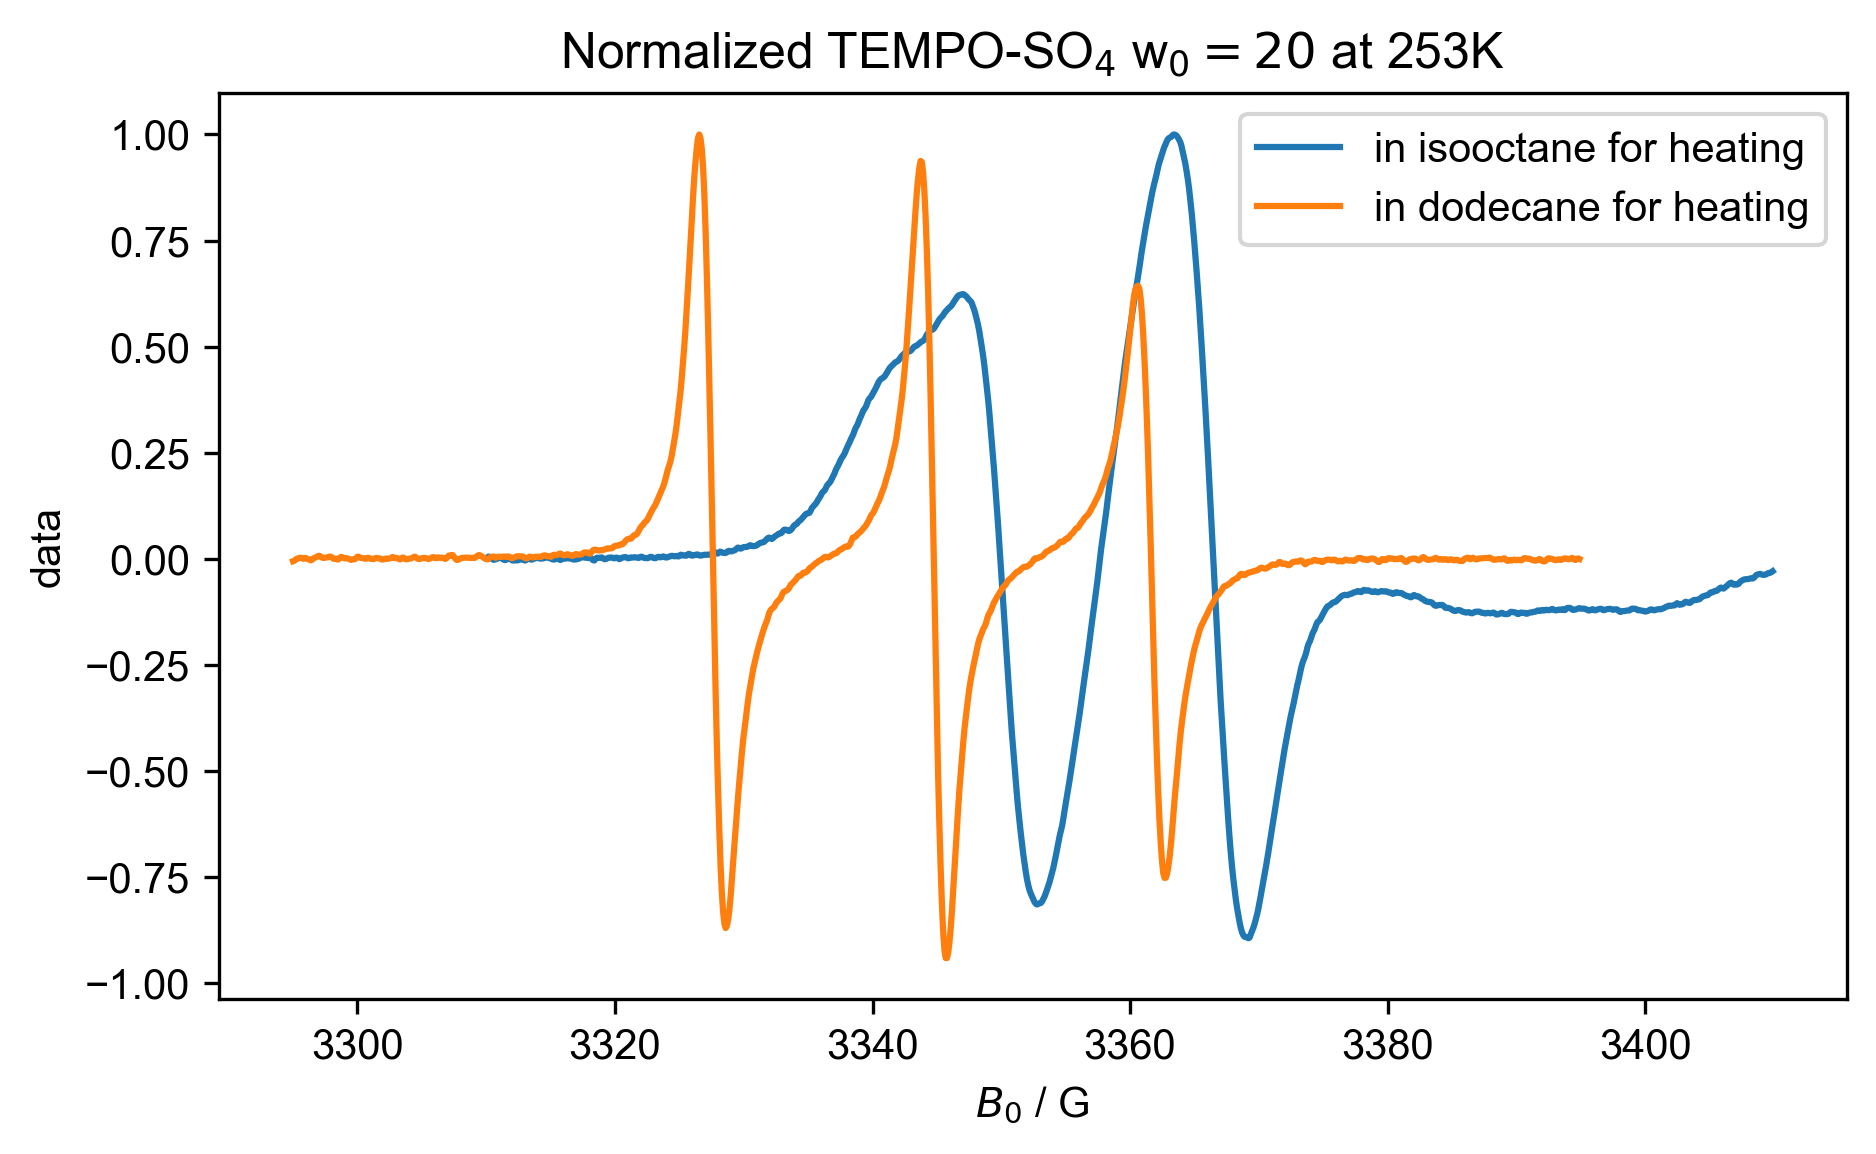

In [20]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 253] / d1["Temperature": 253].max(), label= "in isooctane for heating")
plot(d2["Temperature": 253] / d2["Temperature": 253].max(), label= "in dodecane for heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ at 253K")
legend()

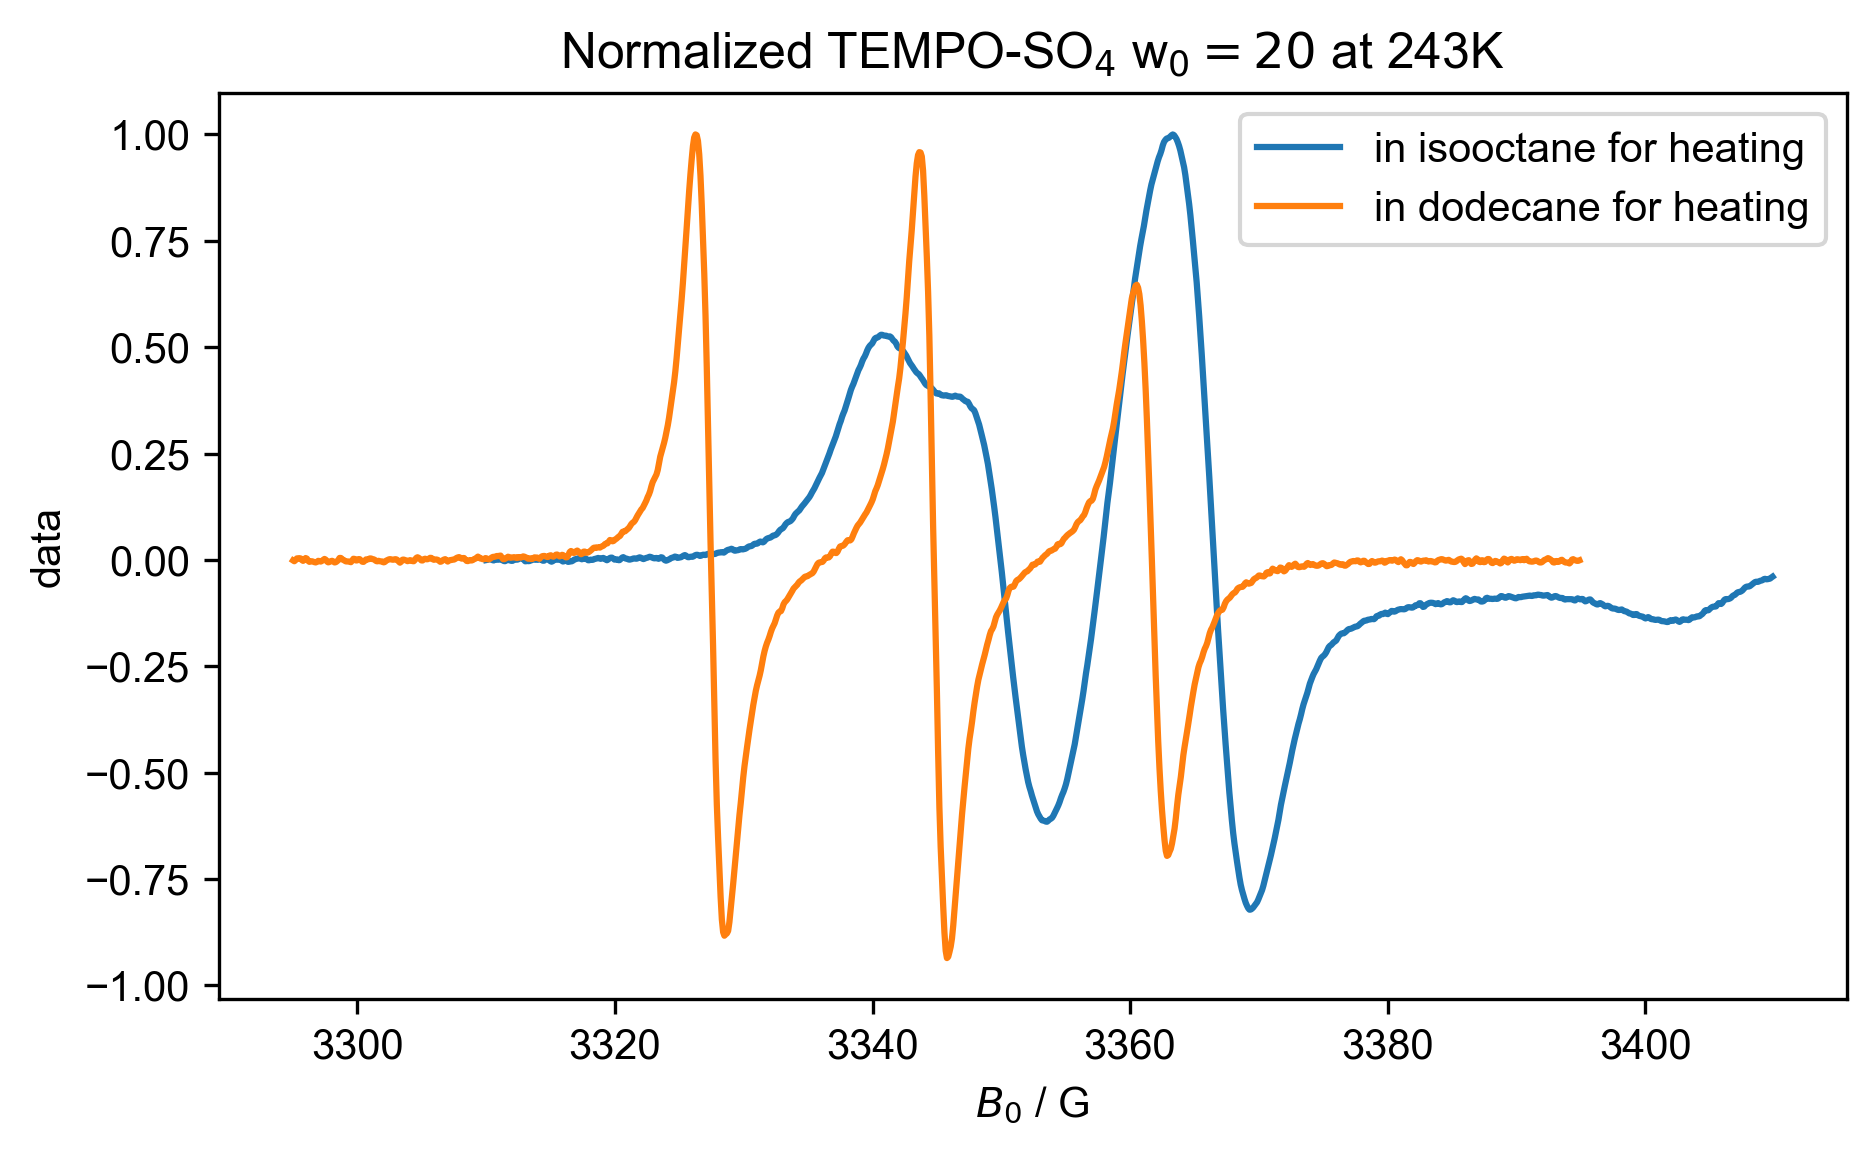

In [21]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 243] / d1["Temperature": 243].max(), label= "in isooctane for heating")
plot(d2["Temperature": 243] / d2["Temperature": 243].max(), label= "in dodecane for heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ at 243K")
legend()

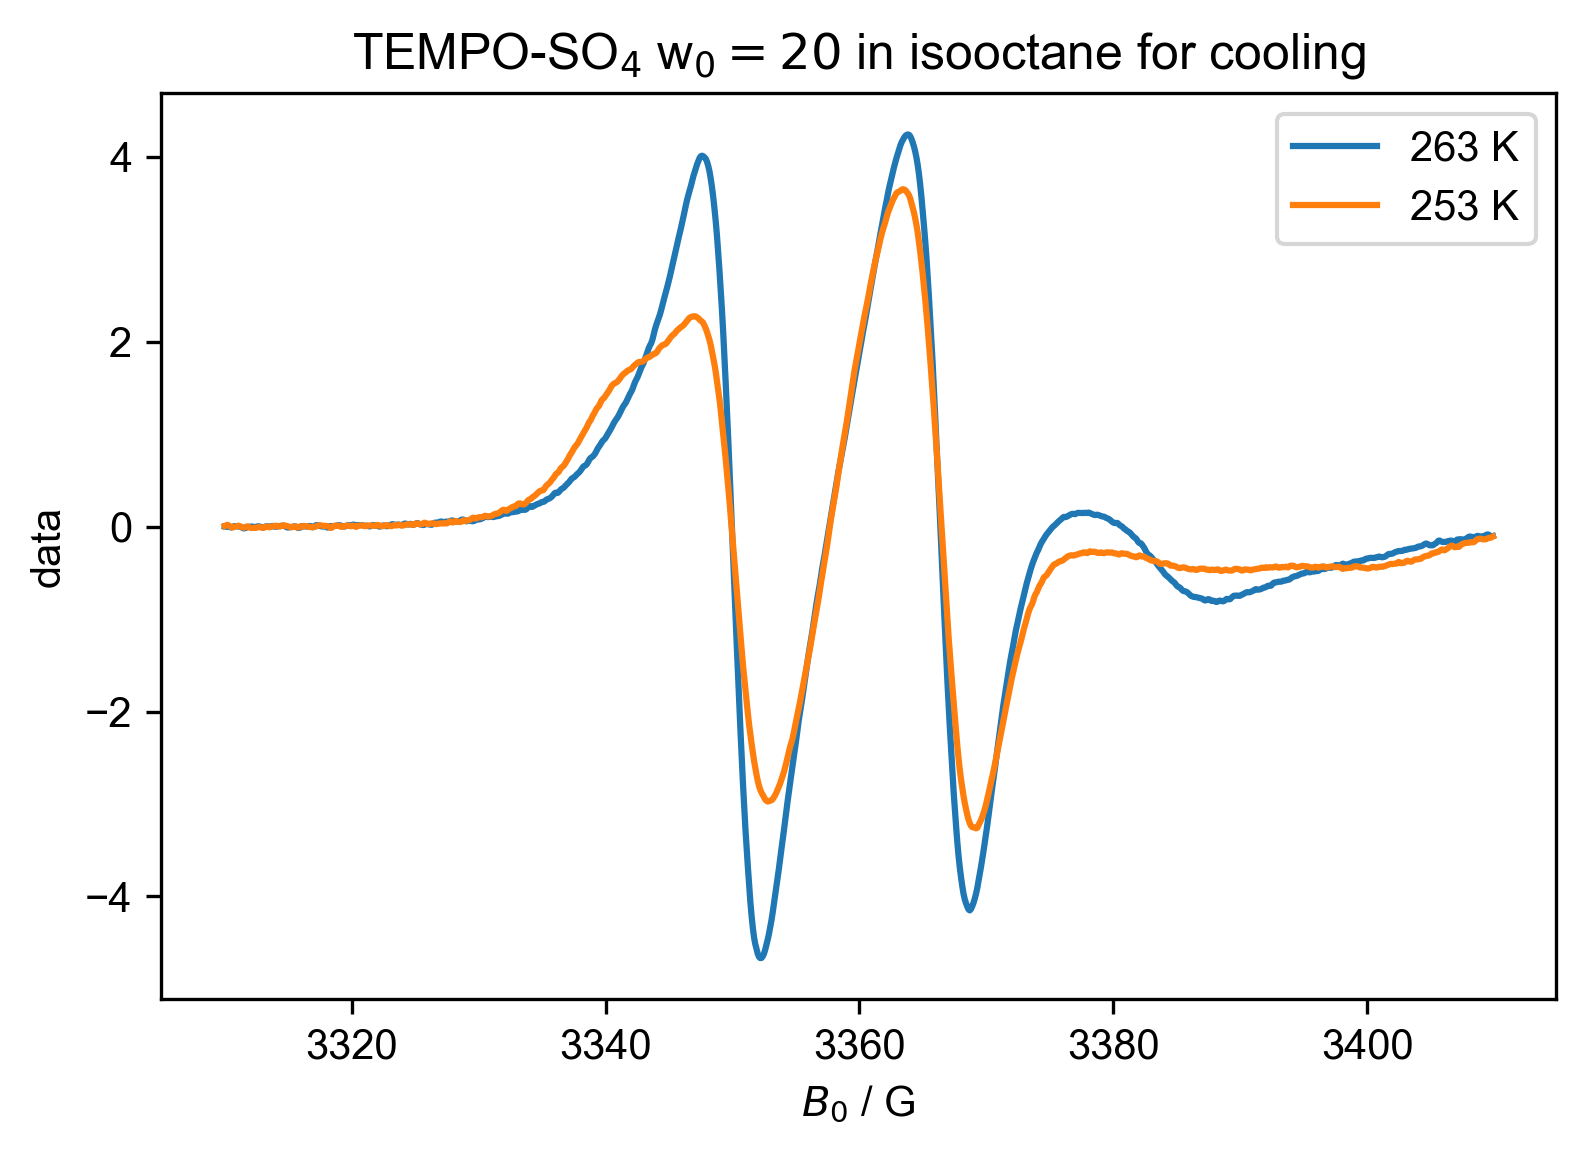

In [22]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="263 K")
plot(d1["Temperature":253], label="253 K")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling")
legend()

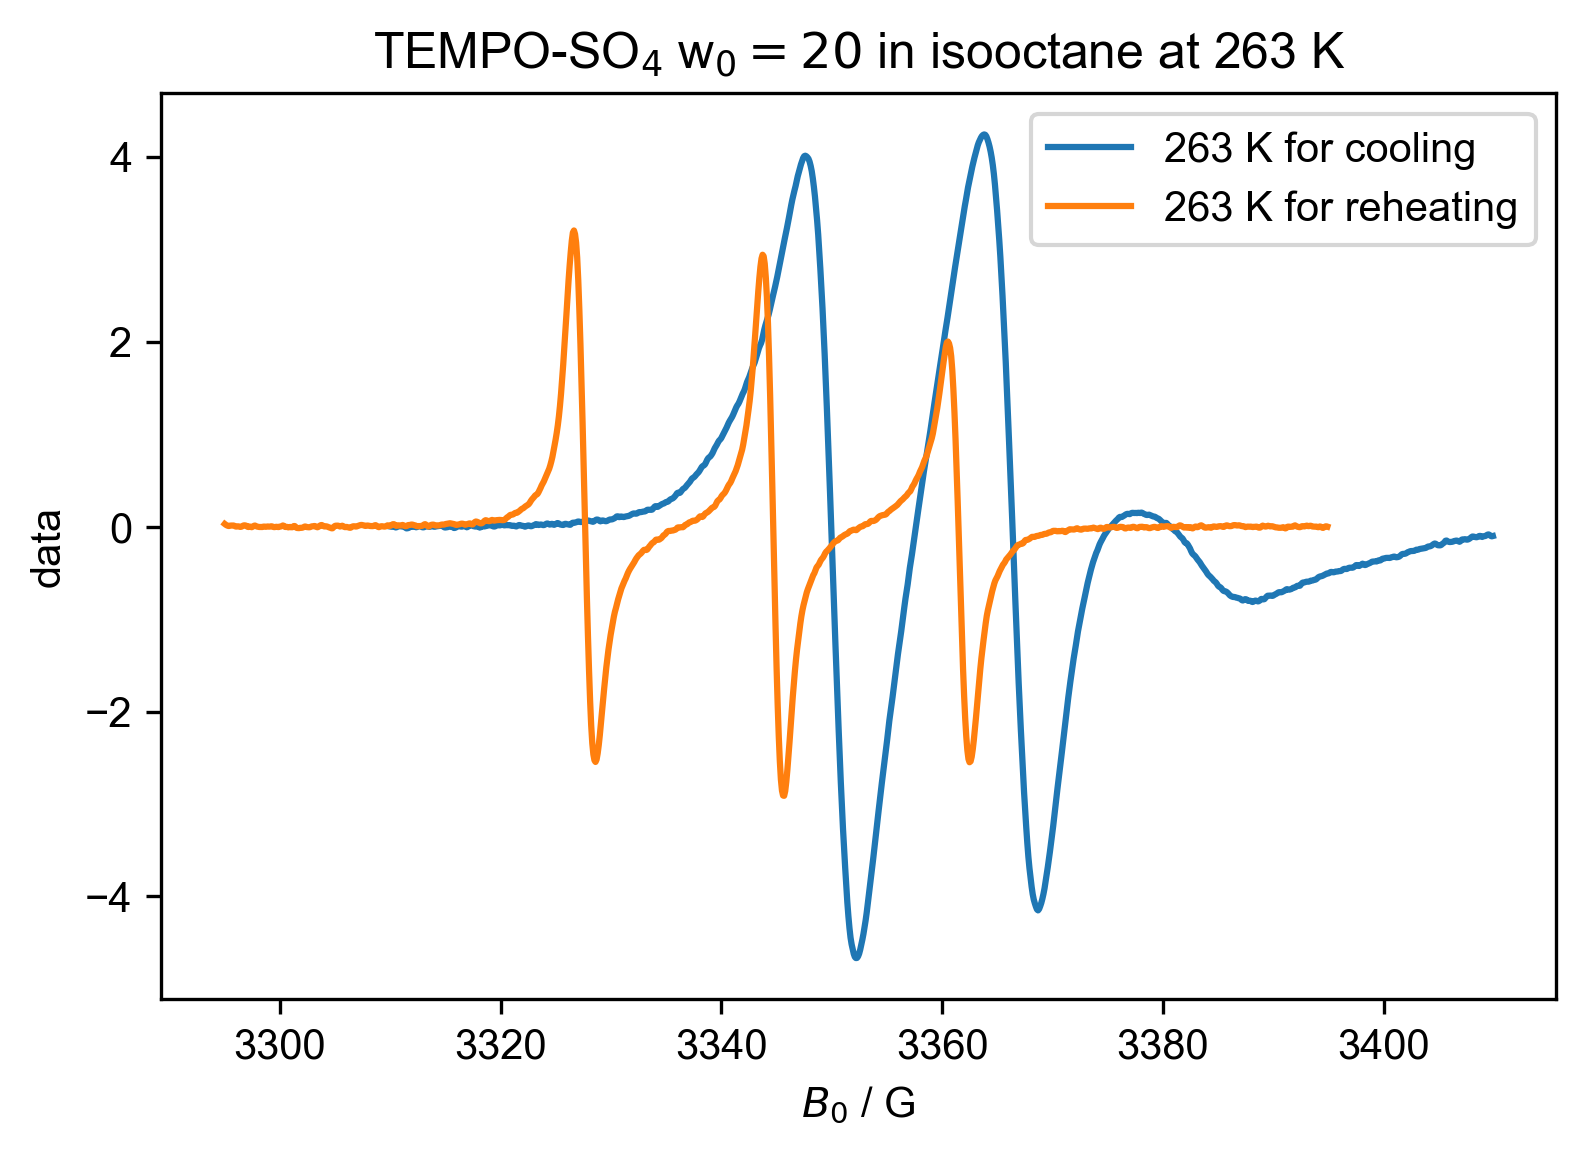

In [23]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="263 K for cooling")
plot(d2["Temperature":263], label="263 K for reheating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane at 263 K")
legend()

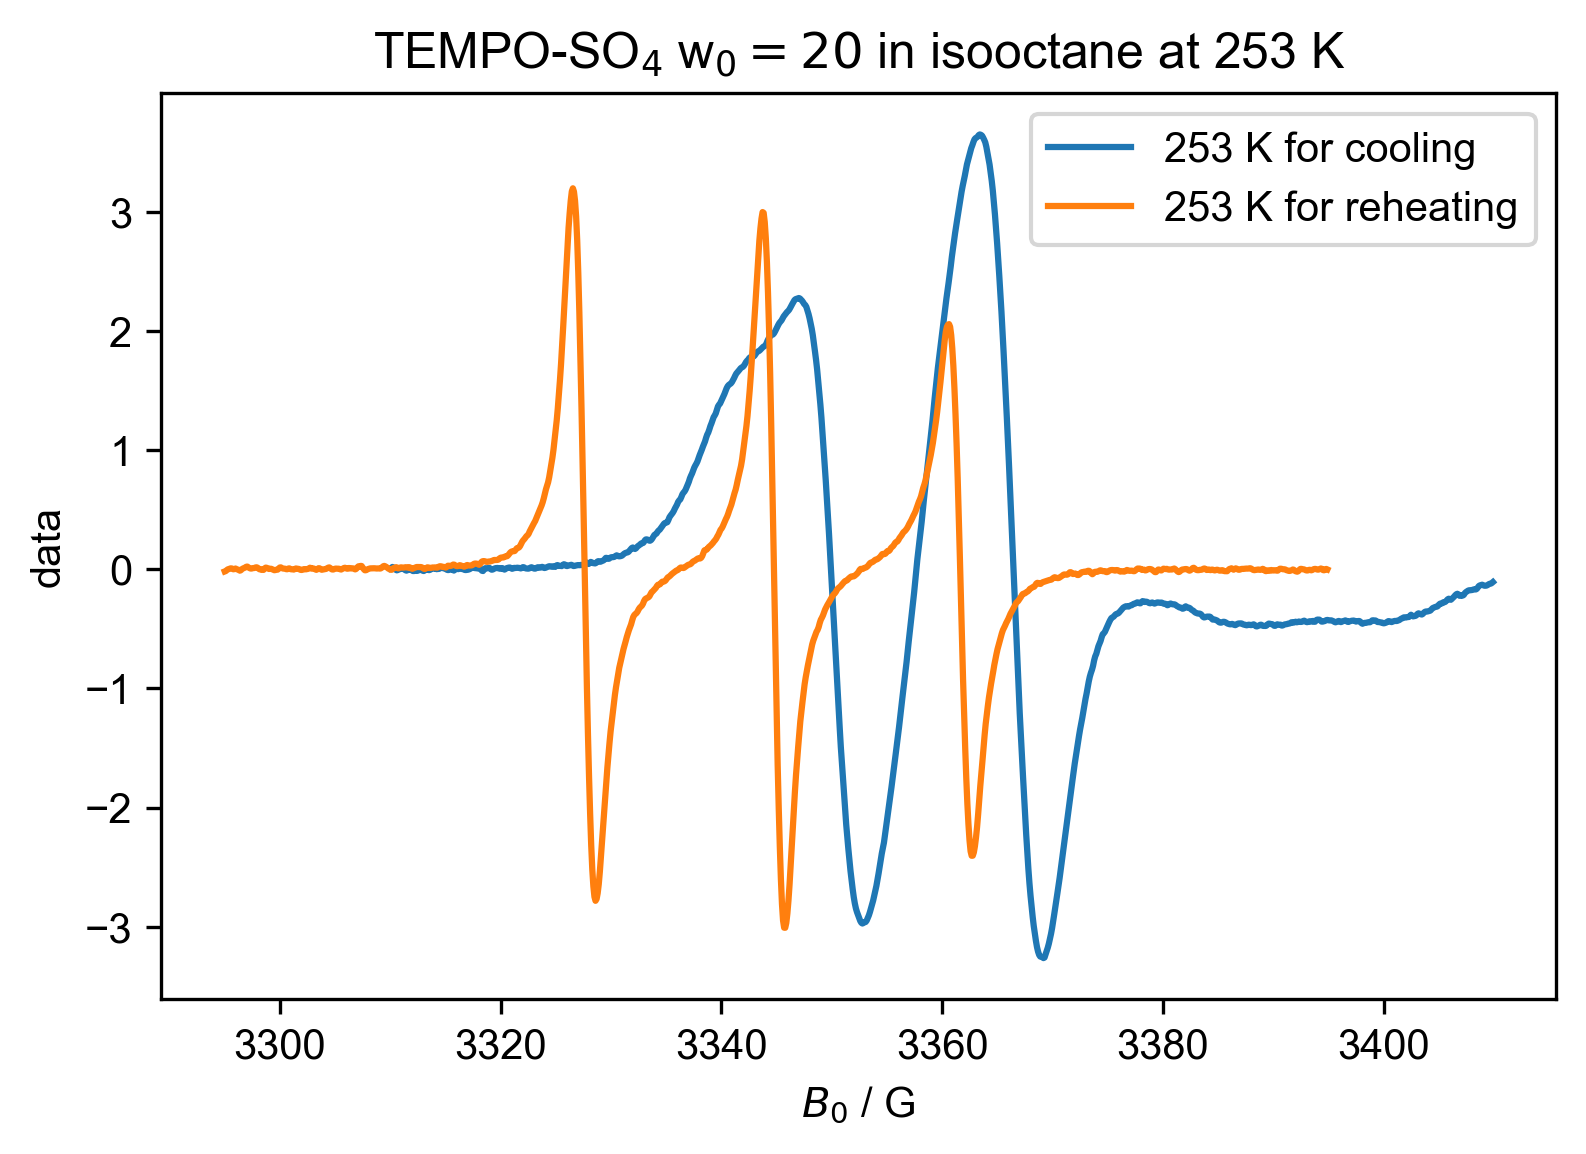

In [24]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="253 K for cooling")
plot(d2["Temperature":253], label="253 K for reheating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane at 253 K")
legend()